# Quantitative Research: 6J Futures (6J) - Multiple Timeframes
## Systematic Trading Approach following TIS Framework

This notebook performs a full Exploratory Data Analysis (AED/EDA) on S&P 500 futures data (6J) from MongoDB, using reusable functions from `utils.py`. We analyze four timeframes: 15min (raw), 1H, 4H, and 1D.

We will:
- Load data from MongoDB using the environment variable `MONGODB_URI_FUTURES_3` and collection `6j_15min`.
- Validate data quality by comparing with Yahoo Finance (using `yfinance`).
- Compute returns and log-returns.
- Analyze distribution: mean, volatility (annualized), skewness, excess kurtosis, Jarque-Bera test, tails (days > 3 sigma), extreme events.
- Analyze volatility regimes: rolling volatility, volatility clustering, recent vs historical volatility.
- Analyze autocorrelation: for lags 1, 5, 20, and plot ACF.
- Compute Hurst exponent to assess mean-reversion vs trending behavior.
- Analyze seasonality (by day of week, month, hour) if date index is available.
- Identify extreme events (largest up/down moves) and their frequency.
- Provide a summary for each timeframe, suggesting which strategy family fits best (mean reversion, momentum, event-driven, etc.).

## IMPORTS AND CONFIG

In [3]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings('ignore')


utils_path = os.path.abspath('../../utils')
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)

from utils import (
    load_data_from_mongo,
    resample_timeframes,
    analyze_timeframe_detailed,
)

print("Imports and configuration complete.")
print(f"Loaded utils from: {utils_path}")

Imports and configuration complete.
Loaded utils from: /Users/luyandy/Documents/AlphaCapital/AlphaCapital-Research/research_development/utils


## LOAD DATA FROM MONGODB 

In [4]:
df_raw = load_data_from_mongo('6j_15min')

print(f"Raw data shape: {df_raw.shape}")
print(f"Date range: {df_raw.index.min()} → {df_raw.index.max()}")
df_raw.head()

Raw data shape: (400158, 5)
Date range: 2009-09-27 18:00:00 → 2026-08-28 16:45:00


,open,high,low,close,volume
time,,,,,
2009-09-27 18:00:00,0.011162,0.011176,0.011160,0.011171,418
2009-09-27 18:15:00,0.011171,0.011208,0.011169,0.011191,895
2009-09-27 18:30:00,0.011191,0.011208,0.011190,0.011204,257
2009-09-27 18:45:00,0.011204,0.011229,0.011204,0.011219,912
2009-09-27 19:00:00,0.011220,0.011323,0.011220,0.011279,2712


## DATA QUALITY CHECK

Comparison with Yahoo Finance (daily closes):
       Mongo_close  Yahoo_close     diff_pct
count  4256.000000  4256.000000  4256.000000
mean      0.009151     0.009140     0.148031
std       0.001836     0.001844     0.386410
min       0.006127     0.006113    -4.089254
25%       0.007737     0.007710    -0.060079
50%       0.009104     0.009096     0.080438
75%       0.009882     0.009879     0.315734
max       0.013196     0.013210     4.935667


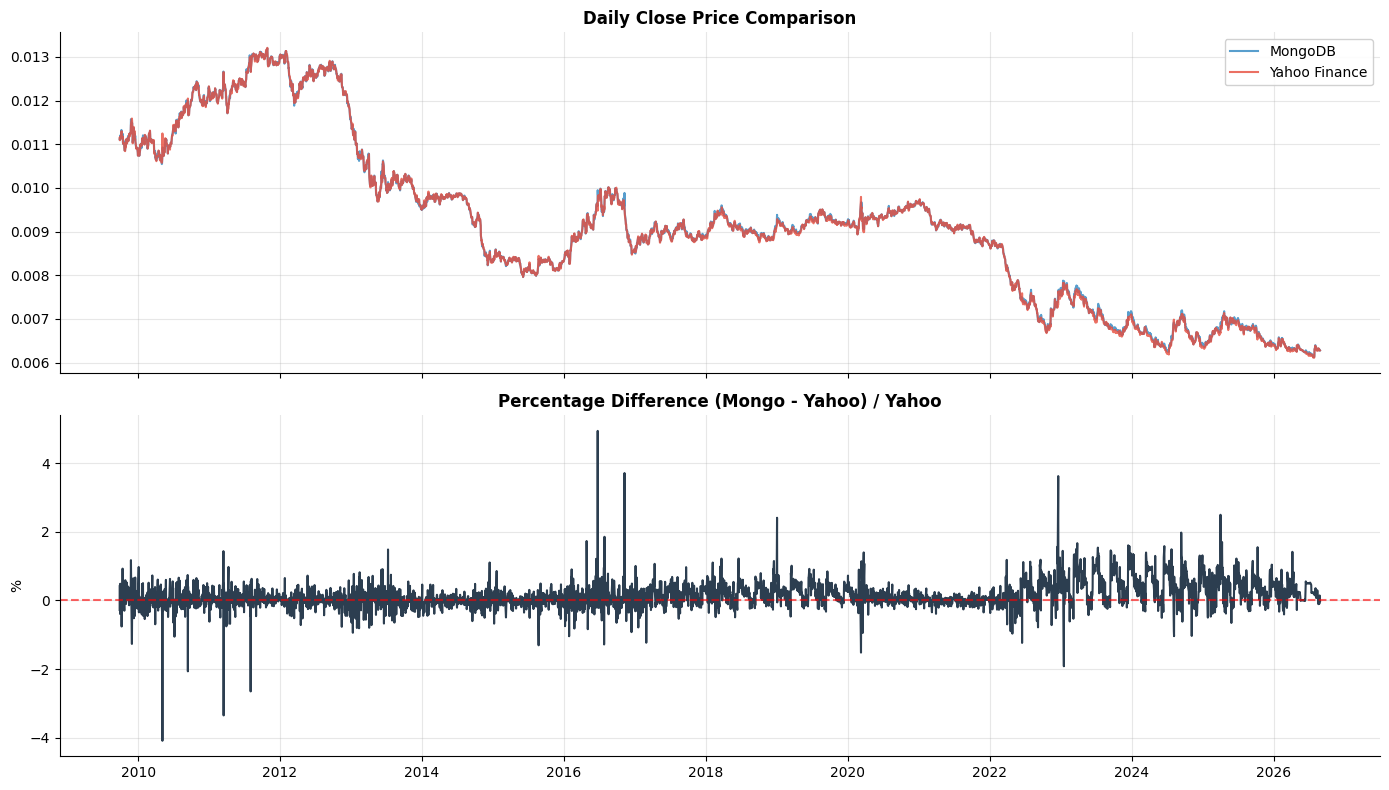

Mean difference: 0.1480%


In [5]:
df_daily = df_raw.resample('D').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
}).dropna()

j6_yahoo = yf.download('6j=F', start=df_daily.index.min(), end=df_daily.index.max(), progress=False)
j6_yahoo = j6_yahoo[['Open', 'High', 'Low', 'Close', 'Volume']]
j6_yahoo.columns = ['open', 'high', 'low', 'close', 'volume']

common_idx = df_daily.index.intersection(j6_yahoo.index)
df_daily_aligned = df_daily.loc[common_idx]
j6_yahoo_aligned = j6_yahoo.loc[common_idx]

comparison = pd.DataFrame({
    'Mongo_close': df_daily_aligned['close'],
    'Yahoo_close': j6_yahoo_aligned['close']
})
comparison['diff_pct'] = (comparison['Mongo_close'] - comparison['Yahoo_close']) / comparison['Yahoo_close'] * 100

print("Comparison with Yahoo Finance (daily closes):")
print(comparison.describe())

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(comparison.index, comparison['Mongo_close'], label='MongoDB', color='#2E86C1', alpha=0.8)
ax1.plot(comparison.index, comparison['Yahoo_close'], label='Yahoo Finance', color='#E74C3C', alpha=0.8)
ax1.set_title('Daily Close Price Comparison', fontweight='bold')
ax1.legend(frameon=True, framealpha=0.9)
ax1.grid(True, alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.plot(comparison.index, comparison['diff_pct'], color='#2C3E50', linewidth=1.5)
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.6)
ax2.set_title('Percentage Difference (Mongo - Yahoo) / Yahoo', fontweight='bold')
ax2.set_ylabel('%')
ax2.grid(True, alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

mean_diff = comparison['diff_pct'].mean()
print(f"Mean difference: {mean_diff:.4f}%")

## RESAMPLE TO MULTIPLE TIMEFRAMES

In [6]:
timeframes = resample_timeframes(df_raw)

print("Timeframes created:")
for name, df in timeframes.items():
    print(f"{name}: {len(df)}")

Timeframes created:
15min: 400158
1H: 100139
4H: 27067
1D: 5264


## ROLL DIAGNOSTIC — outliers vs ES expiration calendar

In [7]:

# --- 1. Isolate days with significant Mongo vs Yahoo discrepancy ---
THRESHOLD_PCT = 1.0  # adjust to be more/less strict

outliers = comparison[comparison['diff_pct'].abs() > THRESHOLD_PCT].copy()
outliers = outliers.sort_values('diff_pct')

print(f"Days with |diff_pct| > {THRESHOLD_PCT}%: {len(outliers)}")
print(outliers[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 2. Generate approximate ES roll calendar (H, M, U, Z contracts) ---
expiry_months = [3, 6, 9, 12]  # March, June, September, December
years = range(df_daily.index.min().year, df_daily.index.max().year + 2)

third_fridays = []
for y in years:
    for m in expiry_months:
        fridays = pd.date_range(f'{y}-{m}-01', f'{y}-{m}-28', freq='W-FRI')
        if len(fridays) >= 3:
            third_fridays.append(fridays[2])

roll_dates = pd.Series(sorted(third_fridays))
ROLL_WINDOW_DAYS = 10  # business days before expiry when the roll typically happens

# --- 3. Cross-check each outlier against the nearest roll window ---
def nearest_roll_distance(date):
    diffs = (roll_dates - date).dt.days
    # we care about the window [-ROLL_WINDOW_DAYS, 0] before expiry
    candidates = diffs[(diffs >= 0) & (diffs <= ROLL_WINDOW_DAYS)]
    return candidates.min() if len(candidates) > 0 else None

outliers['days_to_next_expiry'] = [nearest_roll_distance(d) for d in outliers.index]
outliers['is_roll_window'] = outliers['days_to_next_expiry'].notna()

print("\nOutliers cross-checked against roll calendar:")
print(outliers[['diff_pct', 'days_to_next_expiry', 'is_roll_window']])

pct_explained = outliers['is_roll_window'].mean() * 100
print(f"\n% of outliers explained by roll window: {pct_explained:.1f}%")

# --- 4. Roll flag applied to the FULL daily index (not just outliers) ---
# we'll reuse this later to exclude/flag days in the gap% calculation
df_daily['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily.index
]
print(f"\nTotal days flagged as roll window in the full series: {df_daily['is_roll_window'].sum()}")

Days with |diff_pct| > 1.0%: 133
            Mongo_close  Yahoo_close  diff_pct
2010-05-06     0.010789     0.011249 -4.089254
2011-03-17     0.012231     0.012655 -3.350456
2011-08-03     0.012666     0.013011 -2.651603
2010-09-14     0.011800     0.012049 -2.066560
2023-01-17     0.007669     0.007819 -1.918400
...                 ...          ...       ...
2019-01-02     0.009385     0.009165  2.405890
2025-04-02     0.006846     0.006679  2.492890
2022-12-19     0.007587     0.007322  3.619232
2016-11-08     0.009886     0.009533  3.708170
2016-06-23     0.009950     0.009482  4.935667

[133 rows x 3 columns]

Outliers cross-checked against roll calendar:
            diff_pct  days_to_next_expiry  is_roll_window
2010-05-06 -4.089254                  NaN           False
2011-03-17 -3.350456                  1.0            True
2011-08-03 -2.651603                  NaN           False
2010-09-14 -2.066560                  3.0            True
2023-01-17 -1.918400                  NaN 

## SESSION-DATE DIAGNOSTIC — calendar-day vs trading-session boundary

In [8]:

SESSION_START_HOUR = 18

def to_session_date(timestamp):
    if timestamp.hour >= SESSION_START_HOUR:
        return (timestamp + pd.Timedelta(days=1)).normalize()
    return timestamp.normalize()

df_raw_sess = df_raw.copy()
df_raw_sess['session_date'] = [to_session_date(ts) for ts in df_raw_sess.index]

# --- 2. Rebuild daily bars grouped by session_date instead of calendar day ---
df_daily_session = df_raw_sess.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_session.index.name = 'time'

# --- 3. Re-run the Mongo vs Yahoo comparison using session-based daily bars ---
common_idx_sess = df_daily_session.index.intersection(j6_yahoo.index)
df_daily_session_aligned = df_daily_session.loc[common_idx_sess]
j6_yahoo_aligned_sess = j6_yahoo.loc[common_idx_sess]

comparison_session = pd.DataFrame({
    'Mongo_close': df_daily_session_aligned['close'],
    'Yahoo_close': j6_yahoo_aligned_sess['close']
})
comparison_session['diff_pct'] = (
    (comparison_session['Mongo_close'] - comparison_session['Yahoo_close'])
    / comparison_session['Yahoo_close'] * 100
)

print("Comparison using SESSION-DATE daily bars:")
print(comparison_session.describe())

# --- 4. Compare outlier count before vs after the fix ---
outliers_session = comparison_session[comparison_session['diff_pct'].abs() > THRESHOLD_PCT]
print(f"\nDays with |diff_pct| > {THRESHOLD_PCT}% — calendar-day method: {len(outliers)}")
print(f"Days with |diff_pct| > {THRESHOLD_PCT}% — session-date method:  {len(outliers_session)}")

# --- 5. Check specifically whether the previously "unexplained" dates improve ---
unexplained_dates = outliers[~outliers['is_roll_window']].index
check_unexplained = comparison_session.loc[
    comparison_session.index.intersection(unexplained_dates)
]
print("\nPreviously unexplained outliers, re-measured with session-date bars:")
print(check_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Comparison using SESSION-DATE daily bars:
       Mongo_close  Yahoo_close     diff_pct
count  4256.000000  4256.000000  4256.000000
mean      0.009150     0.009140     0.133482
std       0.001836     0.001844     0.280008
min       0.006126     0.006113    -2.261542
25%       0.007736     0.007710    -0.030690
50%       0.009101     0.009096     0.043473
75%       0.009878     0.009879     0.227154
max       0.013196     0.013210     2.244192

Days with |diff_pct| > 1.0% — calendar-day method: 133
Days with |diff_pct| > 1.0% — session-date method:  58

Previously unexplained outliers, re-measured with session-date bars:
            Mongo_close  Yahoo_close  diff_pct
2009-11-25     0.011452     0.011442  0.087397
2009-11-30     0.011580     0.011591 -0.094897
2010-05-06     0.011053     0.011249 -1.742379
2010-07-07     0.011411     0.011448 -0.323197
2011-08-03     0.012980     0.013011 -0.238261
...                 ...          ...       ...
2025-06-23     0.006907     0.006858  0.707

## COMBINED DIAGNOSTIC — roll + session-date, checking what's left

In [9]:

# --- 1. Re-run outlier detection on the session-date comparison ---
outliers_session_full = comparison_session[
    comparison_session['diff_pct'].abs() > THRESHOLD_PCT
].copy()
outliers_session_full = outliers_session_full.sort_values('diff_pct')

# --- 2. Cross-check these against the roll calendar (reuse nearest_roll_distance) ---
outliers_session_full['days_to_next_expiry'] = [
    nearest_roll_distance(d) for d in outliers_session_full.index
]
outliers_session_full['is_roll_window'] = outliers_session_full['days_to_next_expiry'].notna()

pct_explained_combined = outliers_session_full['is_roll_window'].mean() * 100
print(f"Outliers remaining after session-date fix: {len(outliers_session_full)}")
print(f"% of THOSE explained by roll window: {pct_explained_combined:.1f}%")

# --- 3. Isolate what's still unexplained by EITHER fix ---
still_unexplained = outliers_session_full[~outliers_session_full['is_roll_window']]
still_unexplained = still_unexplained.sort_values('diff_pct', key=abs, ascending=False)

print(f"\nStill unexplained after both fixes: {len(still_unexplained)}")
print(still_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

# --- 4. Flag the worst offenders for manual inspection (likely source-data errors) ---
SEVERE_THRESHOLD = 1.5
severe_unexplained = still_unexplained[still_unexplained['diff_pct'].abs() > SEVERE_THRESHOLD]
print(f"\nSevere unexplained cases (|diff_pct| > {SEVERE_THRESHOLD}%): {len(severe_unexplained)}")
print(severe_unexplained[['Mongo_close', 'Yahoo_close', 'diff_pct']])

Outliers remaining after session-date fix: 58
% of THOSE explained by roll window: 25.9%

Still unexplained after both fixes: 43
            Mongo_close  Yahoo_close  diff_pct
2026-07-30     0.006158     0.006301 -2.261542
2024-05-01     0.006515     0.006372  2.244192
2010-05-06     0.011053     0.011249 -1.742379
2023-12-18     0.007106     0.006994  1.608519
2025-10-10     0.006658     0.006556  1.548199
2023-09-18     0.006875     0.006770  1.543577
2024-03-18     0.006799     0.006702  1.454792
2023-07-17     0.007280     0.007193  1.216460
2022-09-19     0.007051     0.006968  1.198336
2023-12-20     0.007067     0.006985  1.173946
2025-04-02     0.006756     0.006679  1.152869
2024-07-12     0.006406     0.006333  1.152692
2023-10-16     0.006756     0.006679  1.145383
2024-01-11     0.006953     0.006875  1.134546
2023-12-21     0.007135     0.007058  1.090958
2023-05-03     0.007472     0.007392  1.082252
2023-04-13     0.007614     0.007534  1.068488
2024-01-09     0.006998  

# FINAL CLEAN DAILY SERIES — session-date + roll flag combined

In [10]:

df_raw_clean = df_raw.copy()
df_raw_clean['session_date'] = [to_session_date(ts) for ts in df_raw_clean.index]

df_daily_clean = df_raw_clean.groupby('session_date').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum'
})
df_daily_clean.index.name = 'time'

df_daily_clean['is_roll_window'] = [
    nearest_roll_distance(d) is not None for d in df_daily_clean.index
]

SEVERE_UNEXPLAINED_DATES = pd.to_datetime([
    '2025-04-02', '2026-06-05', '2026-07-29', '2020-04-16'
])
df_daily_clean['is_flagged_exception'] = df_daily_clean.index.isin(SEVERE_UNEXPLAINED_DATES)

print(f"Total daily bars: {len(df_daily_clean)}")
print(f"Bars in roll window: {df_daily_clean['is_roll_window'].sum()}")
print(f"Bars flagged as unresolved exceptions: {df_daily_clean['is_flagged_exception'].sum()}")

df_daily_clean.head()

Total daily bars: 4387
Bars in roll window: 604
Bars flagged as unresolved exceptions: 4


,open,high,low,close,volume,is_roll_window,is_flagged_exception
time,,,,,,,
2009-09-28,0.011162,0.011341,0.011143,0.011165,102620,False,False
2009-09-29,0.011157,0.011163,0.011070,0.011106,93766,False,False
2009-09-30,0.011100,0.011197,0.011065,0.011152,98455,False,False
2009-10-01,0.011153,0.011189,0.011095,0.011164,77133,False,False
2009-10-02,0.011166,0.011291,0.011122,0.011146,121423,False,False


## GAP% CALCULATION

In [11]:
# --- 1. PRE-CLOSE reference price: last bar at 16:30 ET for each session ---
df_1630 = df_raw[df_raw.index.time == pd.Timestamp('16:30').time()].copy()
df_1630['session_date'] = [to_session_date(ts) for ts in df_1630.index]

close_1630 = df_1630.groupby('session_date')['close'].last()
close_1630.name = 'close_1630'

# --- 2. OPEN reference price: first bar of the session (18:00) ---
open_1800 = df_daily_clean['open']  # already the session open (18:00 bar)

# --- 3. Align: session D's open is compared against D-1's close_1630 ---
gap_df = pd.DataFrame({'open_1800': open_1800})
gap_df['prev_close_1630'] = close_1630.shift(1).reindex(gap_df.index)

gap_df['gap_pct_adj'] = (
    (gap_df['open_1800'] - gap_df['prev_close_1630']) / gap_df['prev_close_1630'] * 100
)

# --- 4. Attach existing flags ---
gap_df['is_roll_window'] = df_daily_clean['is_roll_window']
gap_df['is_flagged_exception'] = df_daily_clean['is_flagged_exception']
gap_df['dow'] = gap_df.index.day_name()

n_before = len(gap_df)
df_gaps_adj = gap_df.dropna(subset=['gap_pct_adj']).copy()
n_dropped = n_before - len(df_gaps_adj)
print(f"Sessions dropped due to missing 16:30 reference bar: {n_dropped}")

roll_gaps_adj = df_gaps_adj[df_gaps_adj['is_roll_window']]['gap_pct_adj']
normal_gaps_adj = df_gaps_adj[~df_gaps_adj['is_roll_window']]['gap_pct_adj']

print("\nADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS")
print(normal_gaps_adj.describe())
print(f"Mean |gap| adjusted: {normal_gaps_adj.abs().mean():.4f}%")

# --- 5. Comparison against old gap — guarded, in case 'normal_gaps' isn't
# defined in this kernel session (e.g. kernel was restarted) ---
if 'normal_gaps' in dir():
    print("\nQuick comparison against the old gap (17:45->18:00):")
    print(f"  Old      — std: {normal_gaps.std():.4f}%, mean|gap|: {normal_gaps.abs().mean():.4f}%")
    print(f"  Adjusted — std: {normal_gaps_adj.std():.4f}%, mean|gap|: {normal_gaps_adj.abs().mean():.4f}%")
else:
    print("\n[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.")

# --- 6. Diagnostic: which sessions are missing the 16:30 bar? ---
dropped_sessions = gap_df[gap_df['gap_pct_adj'].isna()].index
print(f"\nExamples of sessions without a 16:30 bar ({len(dropped_sessions)} total):")
print(dropped_sessions[:20])

print("\nDropped sessions by year:")
print(dropped_sessions.year.value_counts().sort_index())

Sessions dropped due to missing 16:30 reference bar: 153

ADJUSTED GAP% (16:30 -> 18:00) — NORMAL DAYS
count    3631.000000
mean       -0.004150
std         0.137861
min        -1.458241
25%        -0.032733
50%         0.000000
75%         0.026476
max         1.885259
Name: gap_pct_adj, dtype: float64
Mean |gap| adjusted: 0.0613%

[skip] 'normal_gaps' not in scope — run the original gap_pct cell first if you want the old-vs-new comparison.

Examples of sessions without a 16:30 bar (153 total):
DatetimeIndex(['2009-09-28', '2009-10-09', '2009-11-26', '2009-11-27',
               '2009-12-24', '2010-01-15', '2010-01-18', '2010-02-12',
               '2010-02-15', '2010-04-02', '2010-05-28', '2010-05-31',
               '2010-07-02', '2010-07-05', '2010-09-03', '2010-09-06',
               '2010-10-08', '2010-11-25', '2010-11-26', '2010-12-31'],
              dtype='datetime64[us]', name='time', freq=None)

Dropped sessions by year:
time
2009     5
2010    15
2011    13
2012    14
2013 

## GAP% DISTRIBUTION — descriptive statistics

ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)
count    3631.000000
mean       -0.004150
std         0.137861
min        -1.458241
25%        -0.032733
50%         0.000000
75%         0.026476
max         1.885259
Name: gap_pct_adj, dtype: float64
Mean |gap|: 0.0613%
Skew: 1.0434
Excess kurtosis: 49.1941

Up gaps: 1627 (44.8%), mean 0.0638%
Down gaps: 1735 (47.8%), mean -0.0685%

  percentile  abs_gap_pct
         50     0.030159
         75     0.059613
         90     0.122537
         95     0.208268
         99     0.633339


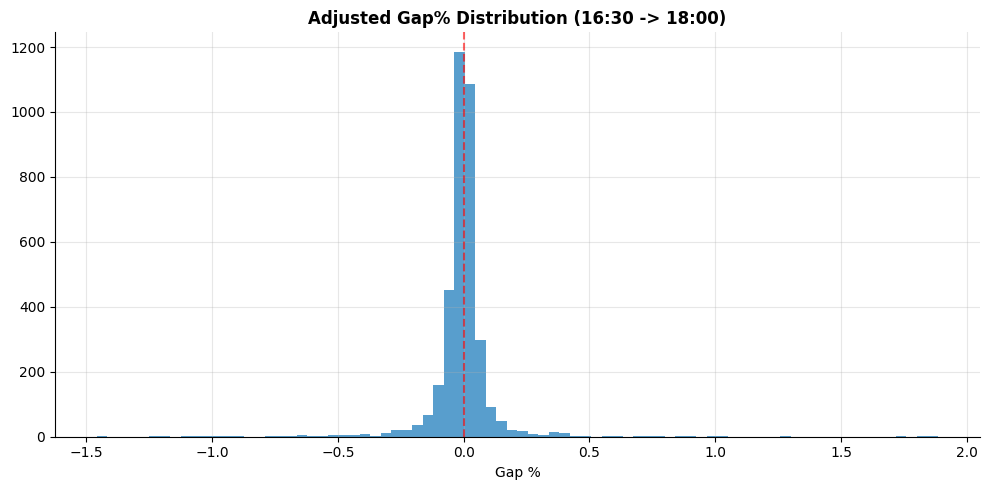

In [12]:
# --- Gap size distribution — descriptive only ---
print("ADJUSTED GAP% DISTRIBUTION (16:30 -> 18:00)")
print(normal_gaps_adj.describe())
print(f"Mean |gap|: {normal_gaps_adj.abs().mean():.4f}%")
print(f"Skew: {normal_gaps_adj.skew():.4f}")
print(f"Excess kurtosis: {normal_gaps_adj.kurt():.4f}")

# Direction split — how often gaps are up vs down, and by how much
up_gaps = normal_gaps_adj[normal_gaps_adj > 0]
down_gaps = normal_gaps_adj[normal_gaps_adj < 0]
print(f"\nUp gaps: {len(up_gaps)} ({len(up_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {up_gaps.mean():.4f}%")
print(f"Down gaps: {len(down_gaps)} ({len(down_gaps)/len(normal_gaps_adj)*100:.1f}%), mean {down_gaps.mean():.4f}%")

# Percentile table — where the mass of the distribution sits
percentiles = [50, 75, 90, 95, 99]
pct_table = pd.DataFrame({
    'percentile': percentiles,
    'abs_gap_pct': [normal_gaps_adj.abs().quantile(p/100) for p in percentiles]
})
print("\n", pct_table.to_string(index=False))

# Optional: quick histogram, same visual style as the rest of the notebook
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(normal_gaps_adj, bins=80, color='#2E86C1', alpha=0.8)
ax.axvline(0, color='red', linestyle='--', alpha=0.6)
ax.set_title('Adjusted Gap% Distribution (16:30 -> 18:00)', fontweight='bold')
ax.set_xlabel('Gap %')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## GAP% SEASONALITY — day of week

Gap by day of week:
               mean       std  count
dow                                 
Monday    -0.001480  0.233763  818.0
Tuesday   -0.003032  0.122772  875.0
Wednesday -0.003706  0.084005  873.0
Thursday   0.005024  0.119035  861.0
Friday     0.020524  0.177995  807.0
Sunday          NaN       NaN    NaN

No sessions flagged as Sunday — check to_session_date() logic


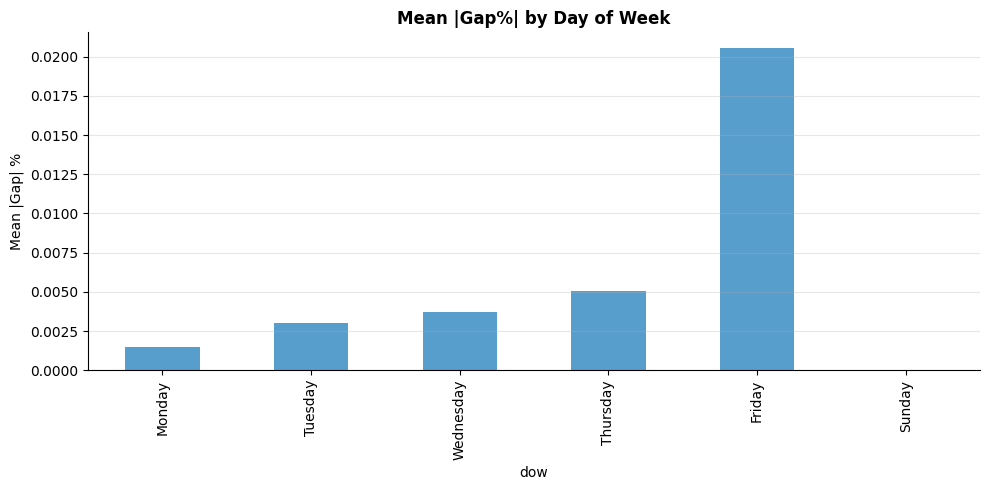

In [13]:
gap_by_dow = df_gaps_adj.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
gap_by_dow = gap_by_dow.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday'])
print("Gap by day of week:")
print(gap_by_dow)

if 'Sunday' in df_gaps_adj['dow'].values:
    print("\nWeekend gap (Sunday reopen):")
    print(df_gaps_adj[df_gaps_adj['dow'] == 'Sunday']['gap_pct_adj'].describe())
else:
    print("\nNo sessions flagged as Sunday — check to_session_date() logic")

fig, ax = plt.subplots(figsize=(10, 5))
gap_by_dow['mean'].abs().plot(kind='bar', ax=ax, color='#2E86C1', alpha=0.8)
ax.set_title('Mean |Gap%| by Day of Week', fontweight='bold')
ax.set_ylabel('Mean |Gap| %')
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## DATA COMPLETENESS CHECK: BARS PER SESSION

In [14]:
# --- Data completeness check: bars per session by year ---
session_dates = [to_session_date(ts) for ts in df_raw.index]
bars_per_session = pd.Series(session_dates).value_counts().sort_index()
bars_per_session = bars_per_session.to_frame('n_bars')
bars_per_session['year'] = bars_per_session.index.year

# A full 18:00->17:45 session should have ~94-95 bars of 15min (23.75h)
print("Bars per session — summary by year:")
print(bars_per_session.groupby('year')['n_bars'].describe())

# Flag sessions with meaningfully fewer bars than expected
EXPECTED_BARS = 90  # conservative floor; adjust after seeing the describe() above
incomplete = bars_per_session[bars_per_session['n_bars'] < EXPECTED_BARS]
print(f"\nSessions with < {EXPECTED_BARS} bars: {len(incomplete)}")
print(incomplete.groupby('year').size())

Bars per session — summary by year:
      count       mean        std   min   25%   50%   75%   max
year                                                           
2009   68.0  91.220588   3.208411  76.0  92.0  92.0  92.0  92.0
2010  259.0  91.343629   3.118100  68.0  92.0  92.0  92.0  92.0
2011  258.0  91.294574   3.948901  44.0  92.0  92.0  92.0  92.0
2012  259.0  90.980695   5.177060  44.0  92.0  92.0  92.0  92.0
2013  258.0  91.093023   4.997185  44.0  92.0  92.0  92.0  92.0
2014  259.0  90.880309   6.815762   4.0  92.0  92.0  92.0  93.0
2015  259.0  91.347490   3.146750  69.0  92.0  92.0  92.0  93.0
2016  258.0  91.569767   2.581922  76.0  92.0  92.0  92.0  92.0
2017  257.0  91.568093   2.586819  76.0  92.0  92.0  92.0  92.0
2018  258.0  91.503876   2.737900  76.0  92.0  92.0  92.0  92.0
2019  258.0  91.465116   2.828555  76.0  92.0  92.0  92.0  92.0
2020  259.0  91.513514   2.731316  76.0  92.0  92.0  92.0  92.0
2021  259.0  91.482625   2.933812  69.0  92.0  92.0  92.0  92.0
2022

## DATA COMPLETENESS — recalibrated threshold, isolating genuine gap

In [15]:
# Recalibrate: most 'normal' sessions cluster at 91-93 bars (daily maintenance
# break accounts for ~2-4 missing bars). A session with drastically fewer bars
# (holidays give partial data, not near-zero) is the real signal.
LOWER_THRESHOLD = 80

truly_broken = bars_per_session[bars_per_session['n_bars'] < LOWER_THRESHOLD]
print(f"Sessions with < {LOWER_THRESHOLD} bars (likely genuine data gaps): {len(truly_broken)}")
print(truly_broken.groupby('year').size())
print("\nWorst offenders:")
print(truly_broken.sort_values('n_bars').head(20))

Sessions with < 80 bars (likely genuine data gaps): 141
year
2009     3
2010     9
2011     8
2012    11
2013    10
2014    11
2015     9
2016     7
2017     7
2018     8
2019     8
2020     8
2021     8
2022     1
2023     2
2024     1
2025     3
2026    27
dtype: int64

Worst offenders:
            n_bars  year
2014-03-09       4  2014
2026-07-04      17  2026
2026-06-20      17  2026
2026-08-01      33  2026
2026-05-09      33  2026
2026-05-23      33  2026
2026-05-30      33  2026
2026-06-06      33  2026
2026-05-02      33  2026
2026-06-13      33  2026
2026-05-16      33  2026
2026-07-11      33  2026
2026-07-18      33  2026
2026-07-25      33  2026
2026-06-27      33  2026
2025-11-28      41  2025
2012-12-26      44  2012
2013-01-02      44  2013
2014-01-02      44  2014
2013-12-26      44  2013


## WEEKEND VS WEEKDAY GAP — separating Friday->Sunday reopen from intra-week gaps

In [16]:
# --- Separate weekend gap from weekday gaps ---
# "Monday"-labeled sessions actually correspond to Sunday's 18:00 reopen,
# because to_session_date() rolls Sunday hour>=18 into the next calendar day.
df_gaps_adj['prev_session_dow'] = df_gaps_adj.index.to_series().shift(1).dt.day_name()

is_weekend_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] == 'Friday')
df_gaps_adj['gap_type'] = 'weekday'
df_gaps_adj.loc[is_weekend_gap, 'gap_type'] = 'weekend'

print("Weekend gap (Fri close -> Sun 18:00 reopen):")
print(df_gaps_adj[df_gaps_adj['gap_type'] == 'weekend']['gap_pct_adj'].describe())

print("\n'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):")
print(df_gaps_adj[(df_gaps_adj['dow'] == 'Monday') & (~is_weekend_gap)][['gap_pct_adj', 'prev_session_dow']])

print("\nWeekday-only gaps (true intra-week, Tue-Fri):")
weekday_only = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
gap_by_dow_clean = weekday_only.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count'])
print(gap_by_dow_clean.reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

# --- Correction: extend the weekend/holiday flag to any gap where 1+ extra
# session was skipped (previous session wasn't literally the immediate prior
# calendar day) — catches Thanksgiving, July 4th, Christmas, Good Friday etc.
df_gaps_adj['days_since_prev_session'] = (
    df_gaps_adj.index.to_series() - df_gaps_adj.index.to_series().shift(1)
).dt.days

is_extended_gap = (df_gaps_adj['dow'] == 'Monday') & (df_gaps_adj['prev_session_dow'] != 'Friday')
df_gaps_adj.loc[is_extended_gap, 'gap_type'] = 'holiday_extended'

print(f"\nHoliday-extended gaps (Friday session missing, or more): {is_extended_gap.sum()}")
print(df_gaps_adj[is_extended_gap][['gap_pct_adj', 'prev_session_dow', 'days_since_prev_session']].describe())

# Re-run the clean weekday-only table, now properly excluding weekend AND holiday-extended
weekday_only_clean = df_gaps_adj[df_gaps_adj['gap_type'] == 'weekday']
print("\nCorrected weekday-only gap stats (true Tue-Fri, no contamination):")
print(weekday_only_clean.groupby('dow')['gap_pct_adj'].agg(['mean', 'std', 'count']).reindex(['Tuesday', 'Wednesday', 'Thursday', 'Friday']))

Weekend gap (Fri close -> Sun 18:00 reopen):
count    767.000000
mean      -0.006292
std        0.194958
min       -1.189387
25%       -0.062232
50%       -0.007297
75%        0.040412
max        1.803957
Name: gap_pct_adj, dtype: float64

'Monday'-labeled sessions that are NOT weekend gaps (holiday-shifted?):
            gap_pct_adj prev_session_dow
time                                    
2009-10-12    -1.458241         Thursday
2009-11-30     0.865082        Wednesday
2009-12-28     0.045788        Wednesday
2010-01-04     0.046477         Thursday
2010-04-05    -0.891182         Thursday
2010-10-11     1.046042         Thursday
2010-11-29    -0.643167        Wednesday
2010-12-27     0.058009         Thursday
2011-01-03     0.603048         Thursday
2011-04-25     0.073668         Thursday
2011-10-10    -0.191498         Thursday
2011-11-28    -0.177853        Wednesday
2012-04-09     1.004281         Thursday
2012-10-08    -0.219608         Thursday
2012-11-26     0.165017        W

## GAP EXTREME EVENTS — largest gaps and cross-check against flagged exceptions

In [17]:
# --- Extreme gap events — same treatment as the timeframe EDA sections ---
top_up = normal_gaps_adj.sort_values(ascending=False).head(10)
top_down = normal_gaps_adj.sort_values(ascending=True).head(10)

print("Top 10 up gaps:")
print(top_up)
print("\nTop 10 down gaps:")
print(top_down)

# Cross-check: are any of these driven by the still-unresolved flagged exceptions?
flagged_dates = set(df_daily_clean[df_daily_clean['is_flagged_exception']].index)
overlap = (set(top_up.index) | set(top_down.index)) & flagged_dates
print(f"\nFlagged exception dates overlapping top gaps: {overlap}")

Top 10 up gaps:
time
2019-01-03    1.885259
2026-08-03    1.803957
2021-11-29    1.742442
2024-12-02    1.285153
2010-10-11    1.046042
2025-04-07    1.006198
2012-04-09    1.004281
2018-12-26    0.972161
2020-03-09    0.884909
2015-07-06    0.879134
Name: gap_pct_adj, dtype: float64

Top 10 down gaps:
time
2009-10-12   -1.458241
2012-12-26   -1.229370
2015-01-20   -1.219229
2010-05-10   -1.189387
2013-02-19   -1.169482
2025-10-06   -1.083614
2013-09-03   -1.061842
2016-02-16   -1.035595
2017-04-24   -0.996569
2014-12-01   -0.929849
Name: gap_pct_adj, dtype: float64

Flagged exception dates overlapping top gaps: set()


## EXTREME GAPS — cross-check against session data completeness

In [18]:
top_up_dates = normal_gaps_adj.sort_values(ascending=False).head(10).index
top_down_dates = normal_gaps_adj.sort_values(ascending=True).head(10).index
all_top = top_up_dates.append(top_down_dates)

print("Year distribution of top-20 extreme gaps:")
print(all_top.year.value_counts().sort_index())

print("\nBar count on those specific extreme-gap sessions (checking for stale/thin reference data):")
print(bars_per_session.loc[bars_per_session.index.intersection(all_top)].sort_values('n_bars'))

Year distribution of top-20 extreme gaps:
time
2009    1
2010    2
2012    2
2013    2
2014    1
2015    2
2016    1
2017    1
2018    1
2019    1
2020    1
2021    1
2024    1
2025    2
2026    1
Name: count, dtype: int64

Bar count on those specific extreme-gap sessions (checking for stale/thin reference data):
            n_bars  year
2012-12-26      44  2012
2009-10-12      92  2009
2025-04-07      92  2025
2024-12-02      92  2024
2021-11-29      92  2021
2020-03-09      92  2020
2019-01-03      92  2019
2018-12-26      92  2018
2017-04-24      92  2017
2016-02-16      92  2016
2015-07-06      92  2015
2015-01-20      92  2015
2014-12-01      92  2014
2013-09-03      92  2013
2013-02-19      92  2013
2012-04-09      92  2012
2010-10-11      92  2010
2010-05-10      92  2010
2025-10-06      92  2025
2026-08-03      96  2026


## LIQUIDITY AROUND REOPEN — volume in first bars after 18:00

In [19]:
# --- Volume profile: first bars after 18:00 reopen vs rest of session ---
df_raw_hour = df_raw.copy()
df_raw_hour['time_of_day'] = df_raw_hour.index.time
df_raw_hour['session_date'] = [to_session_date(ts) for ts in df_raw_hour.index]

# first 30 minutes after reopen = bars at 18:00 and 18:15
reopen_mask = df_raw_hour['time_of_day'].isin([
    pd.Timestamp('18:00').time(), pd.Timestamp('18:15').time()
])

reopen_vol = df_raw_hour[reopen_mask].groupby('session_date')['volume'].mean()
rest_vol = df_raw_hour[~reopen_mask].groupby('session_date')['volume'].mean()

print("Avg volume — first 30min after 18:00 reopen:")
print(reopen_vol.describe())
print("\nAvg volume — rest of session:")
print(rest_vol.describe())
print(f"\nReopen volume as % of rest-of-session average: "
      f"{(reopen_vol.mean() / rest_vol.mean() * 100):.1f}%")

Avg volume — first 30min after 18:00 reopen:
count     4364.000000
mean       526.359189
std        703.383181
min         18.000000
25%        204.000000
50%        348.250000
75%        604.625000
max      18861.000000
Name: volume, dtype: float64

Avg volume — rest of session:
count    4387.000000
mean     1383.185489
std       635.360175
min       185.032258
25%       975.805556
50%      1271.344444
75%      1640.477778
max      9425.129032
Name: volume, dtype: float64

Reopen volume as % of rest-of-session average: 38.1%


## RUN DETAILED EDA ON EACH TIMEFRAME


ANALYZING 15MIN TIMEFRAME

COMPLETE ANALYSIS: 15min
Bars: 400158
Period: 2009-09-27 18:00:00 → 2026-08-28 16:45:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BEARISH
~-3.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 8.5%
Skewness: 1.73 (right tail)
Excess Kurtosis: 107.43 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 5505 (1.4%)


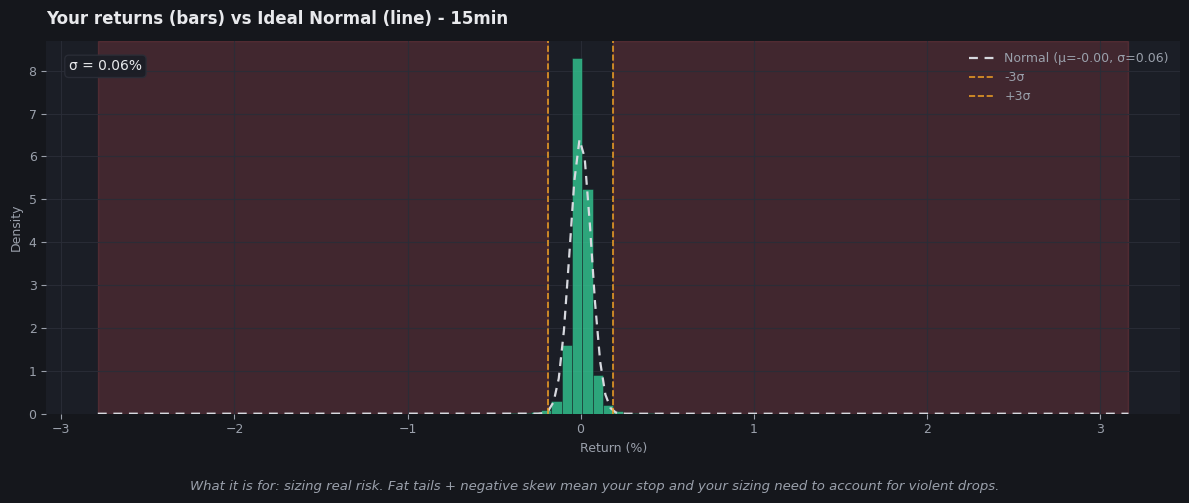


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.36x
Recent volatility (daily): 0.02%
Historical volatility (daily): 0.06%
Comes in waves? low


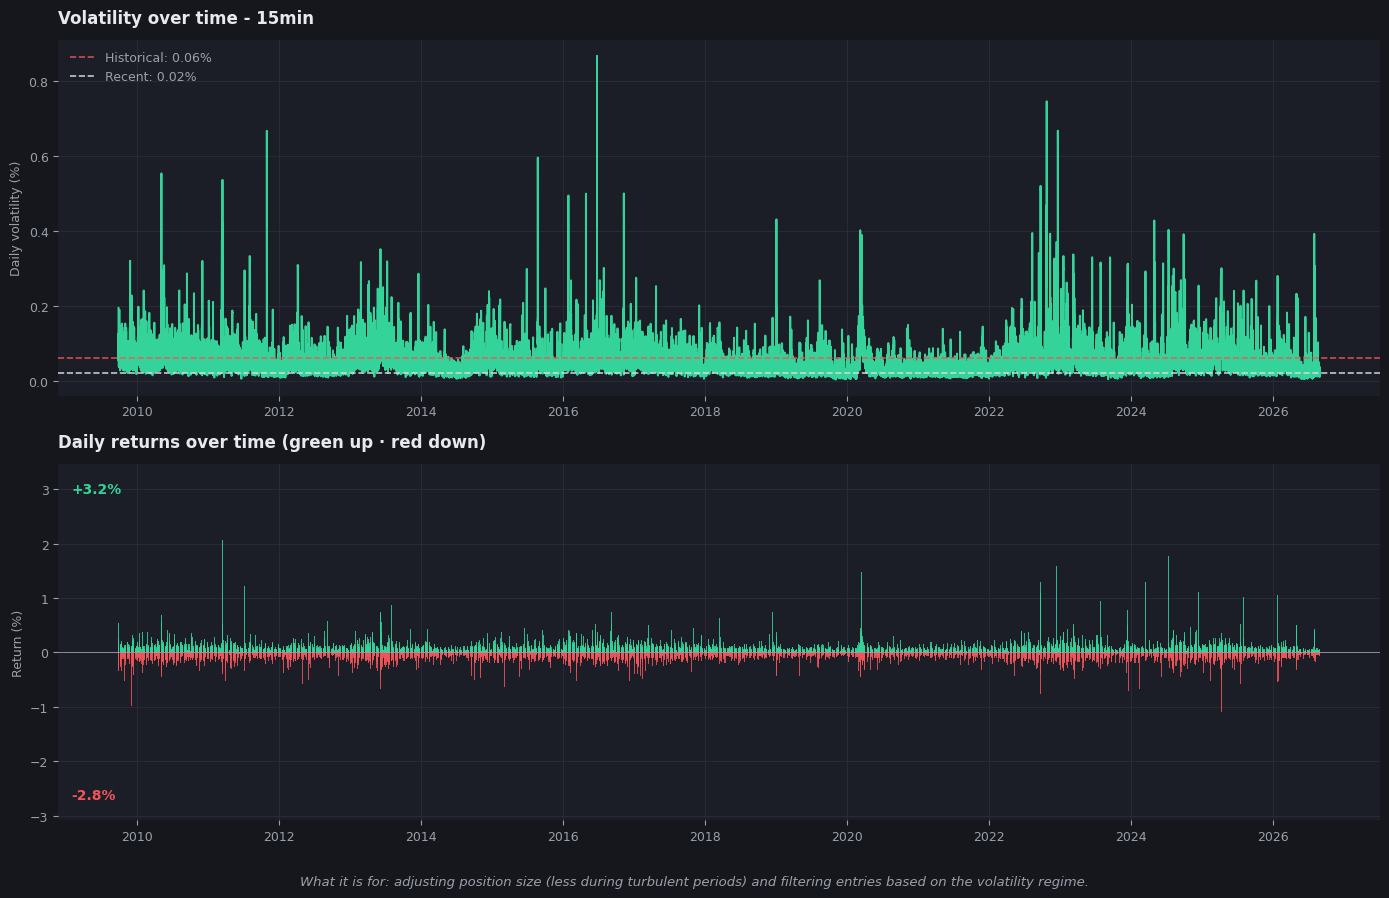


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.00 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


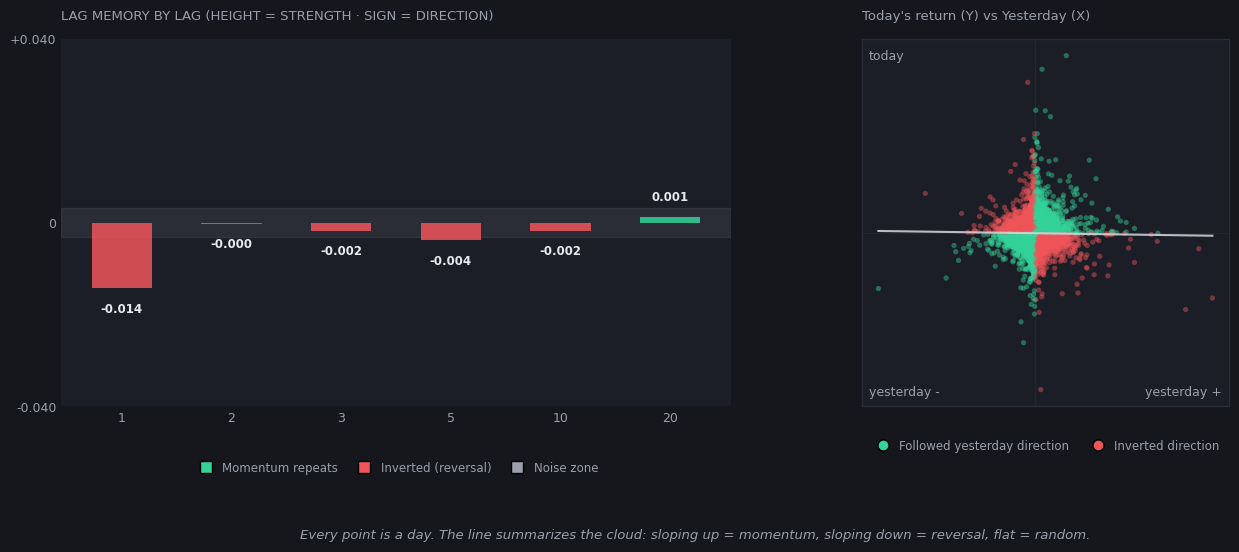


PATTERNS
SEASONALITY?


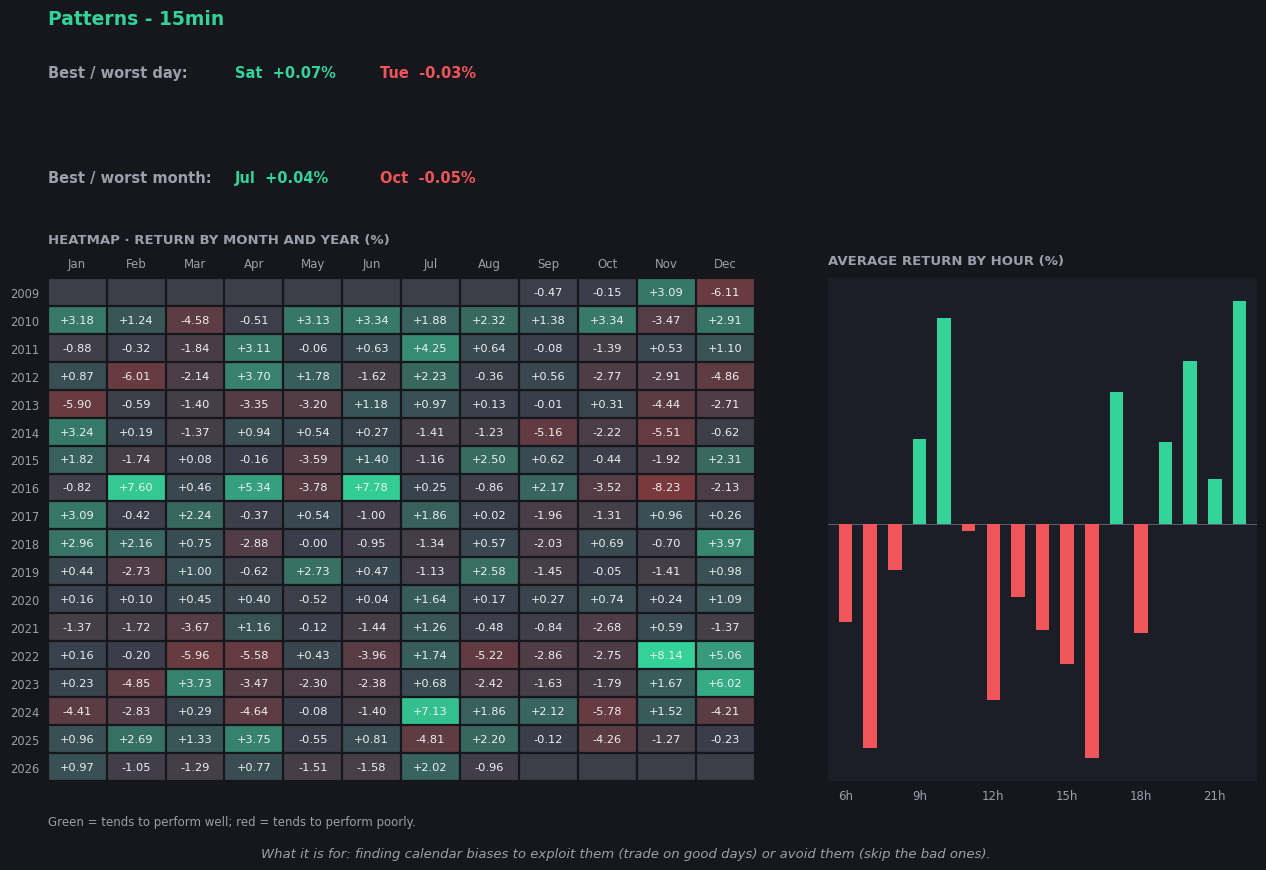


Average return by day of week (Mon-Fri, %):
Mon: -0.01%
Tue: -0.03%
Wed: -0.01%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.01%
Feb: -0.02%
Mar: -0.03%
Apr: -0.01%
May: -0.01%
Jun: 0.00%
Jul: 0.04%
Aug: 0.00%
Sep: -0.02%
Oct: -0.05%
Nov: -0.03%
Dec: 0.00%

Average return by hour (6:00-22:00, %):
06:00: -0.00%
07:00: -0.00%
08:00: -0.00%
09:00: 0.00%
10:00: 0.00%
11:00: -0.00%
12:00: -0.00%
13:00: -0.00%
14:00: -0.00%
15:00: -0.00%
16:00: -0.00%
17:00: 0.00%
18:00: -0.00%
19:00: 0.00%
20:00: 0.00%
21:00: 0.00%
22:00: 0.00%

EXTREME EVENTS
REACTION?


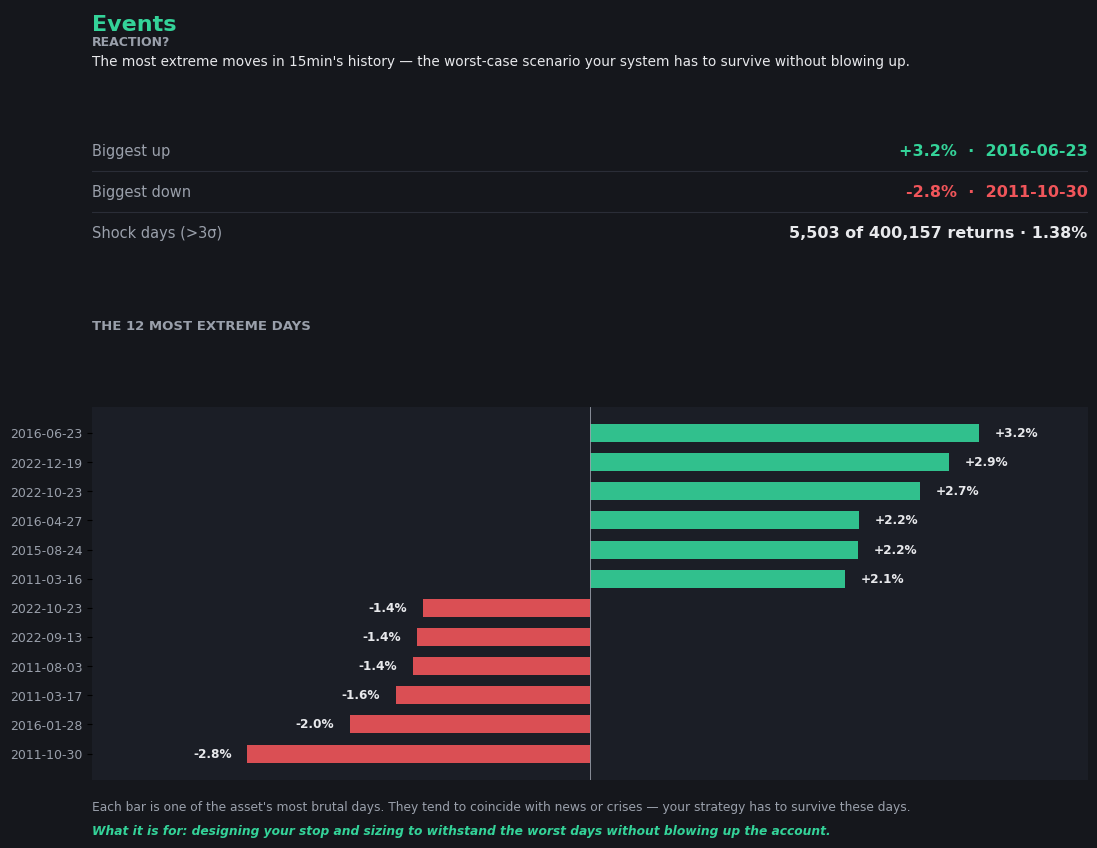

Biggest up: +3.2%
Biggest down: -2.8%
Shock days (>3σ): 5505 of 400,157 returns · 1.38%

Top 12 up days:
+3.2% - 2016-06-23
+2.9% - 2022-12-19
+2.7% - 2022-10-23
+2.2% - 2016-04-27
+2.2% - 2015-08-24
+2.1% - 2011-03-16

Top 12 down days:
-2.8% - 2011-10-30
-2.0% - 2016-01-28
-1.6% - 2011-03-17
-1.4% - 2011-08-03
-1.4% - 2022-09-13
-1.4% - 2022-10-23

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


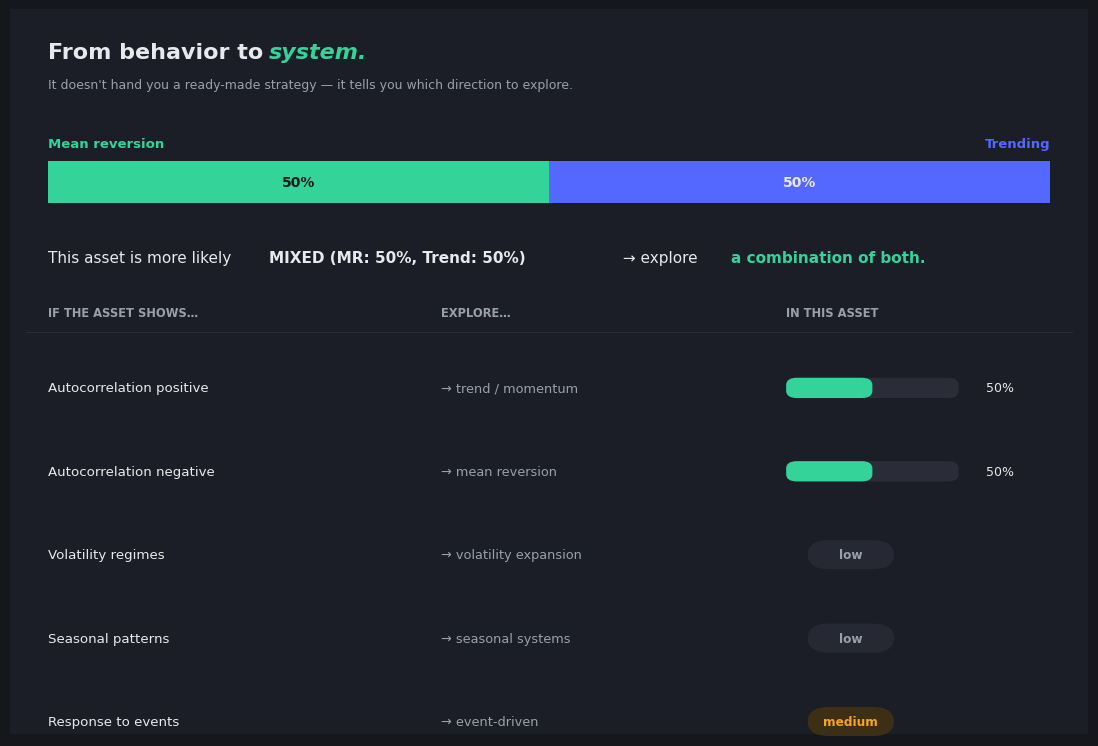


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 8.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 1.73 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 107.43 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.014

Hurst Exponent
Measures price memory. >0.5 = trending.
→ 0.504

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

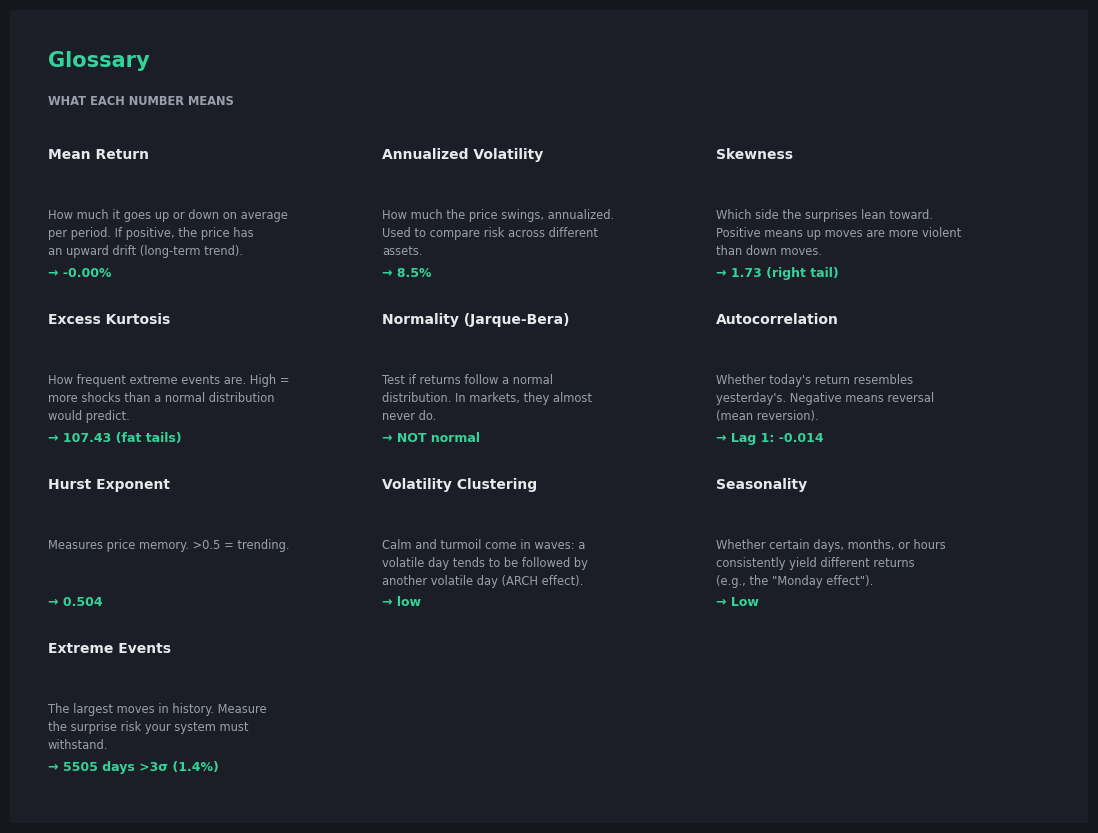




ANALYZING 1H TIMEFRAME

COMPLETE ANALYSIS: 1H
Bars: 100139
Period: 2009-09-27 18:00:00 → 2026-08-28 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.50
BEARISH
~-3.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 8.5%
Skewness: 1.09 (right tail)
Excess Kurtosis: 40.53 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 1513 (1.5%)


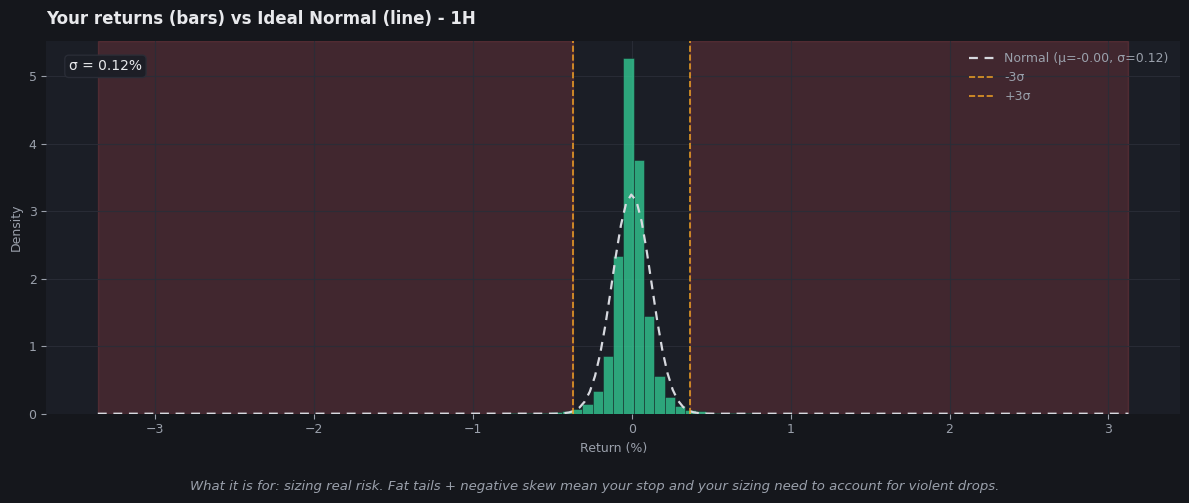


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.44x
Recent volatility (daily): 0.05%
Historical volatility (daily): 0.12%
Comes in waves? low


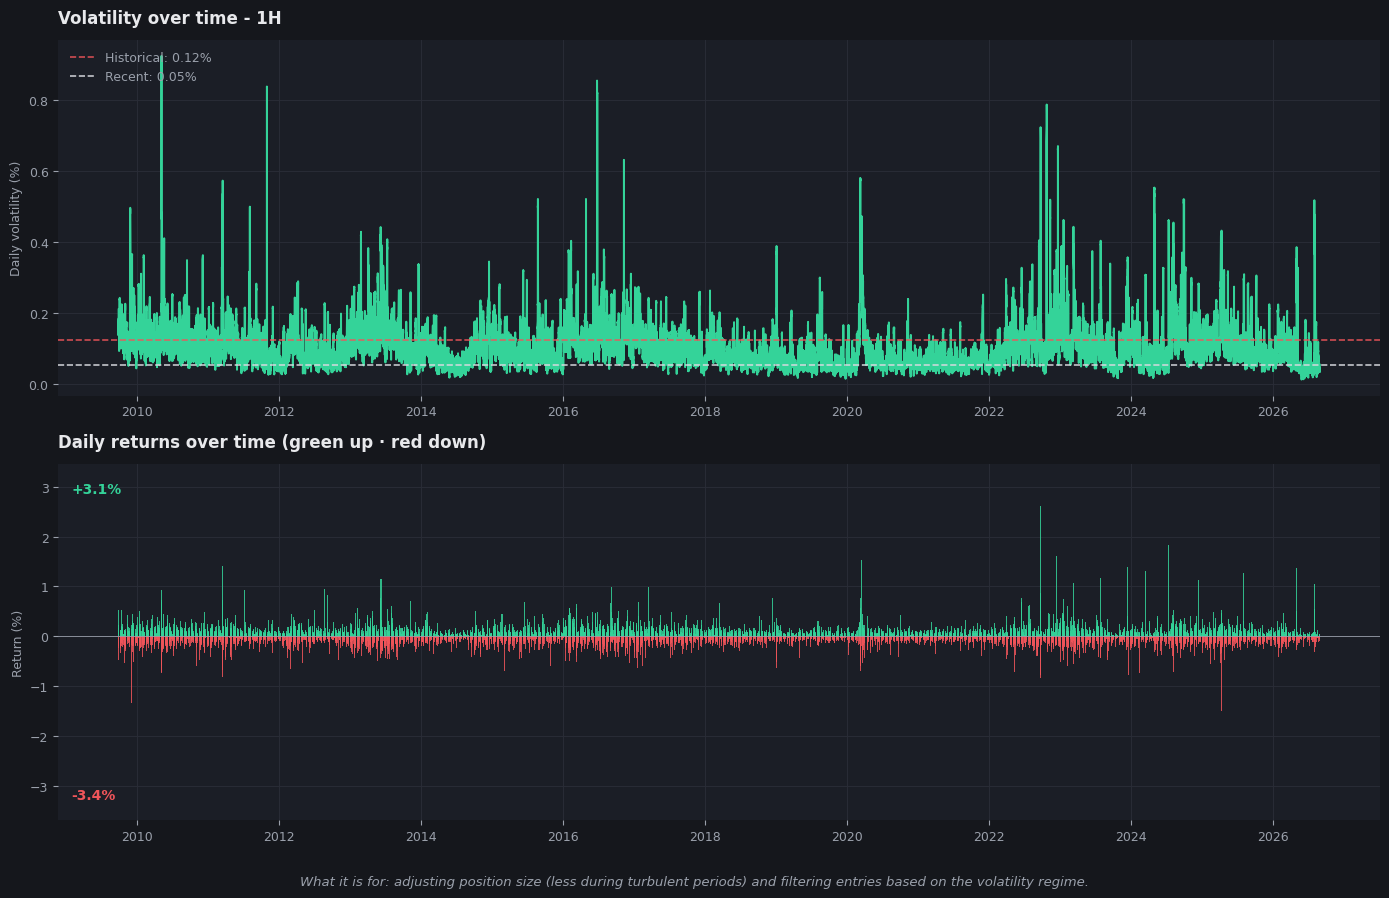


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: -0.00 reverts
Lag 20 · vs 20 days ago: 0.00 ~0


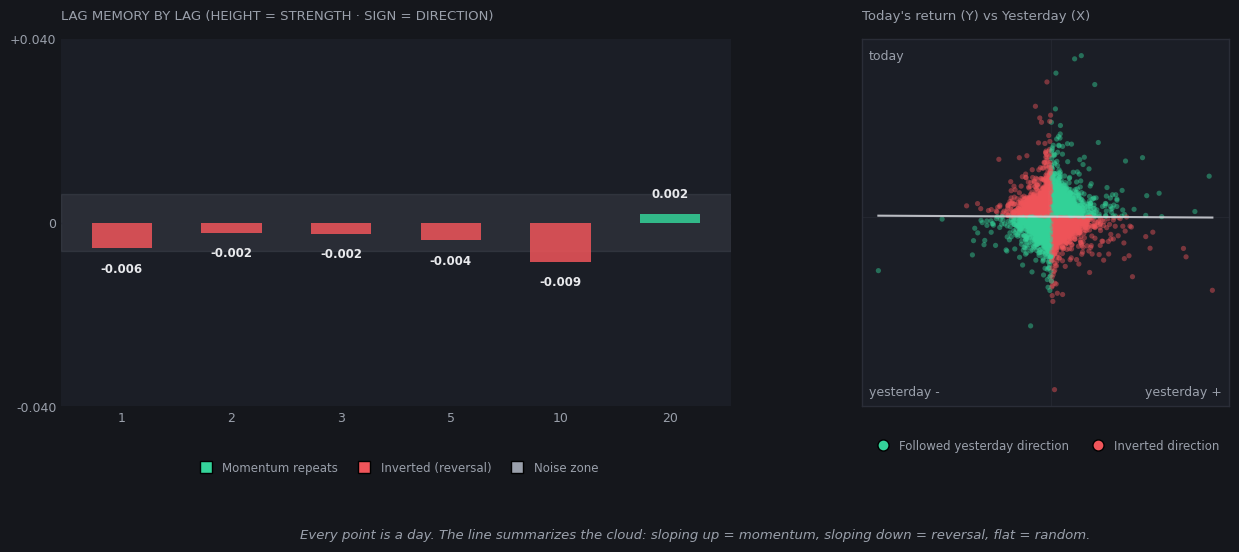


PATTERNS
SEASONALITY?


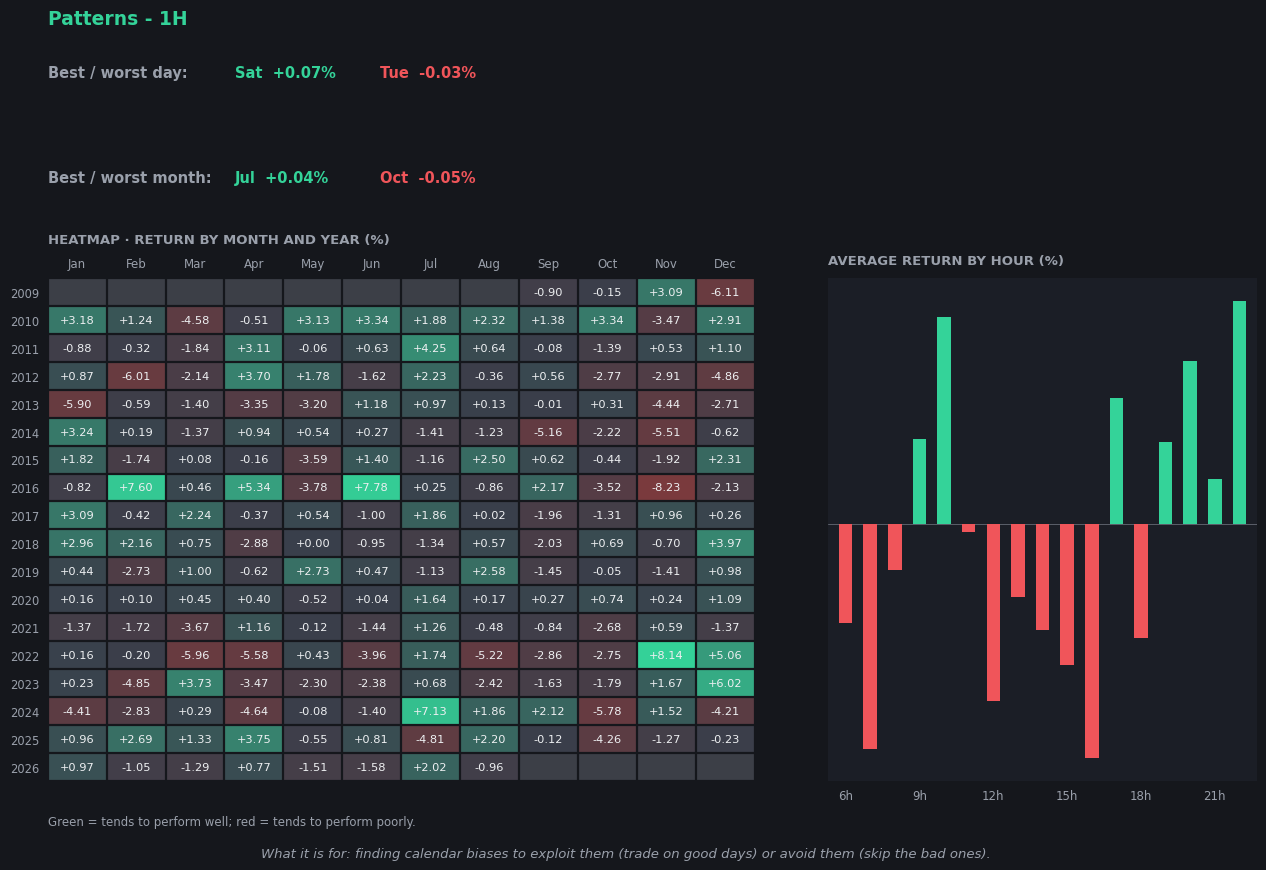


Average return by day of week (Mon-Fri, %):
Mon: -0.01%
Tue: -0.03%
Wed: -0.01%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.01%
Feb: -0.02%
Mar: -0.03%
Apr: -0.01%
May: -0.01%
Jun: 0.00%
Jul: 0.04%
Aug: 0.00%
Sep: -0.02%
Oct: -0.05%
Nov: -0.03%
Dec: 0.00%

Average return by hour (6:00-22:00, %):
06:00: -0.00%
07:00: -0.00%
08:00: -0.00%
09:00: 0.00%
10:00: 0.00%
11:00: -0.00%
12:00: -0.00%
13:00: -0.00%
14:00: -0.00%
15:00: -0.00%
16:00: -0.00%
17:00: 0.00%
18:00: -0.00%
19:00: 0.00%
20:00: 0.00%
21:00: 0.00%
22:00: 0.00%

EXTREME EVENTS
REACTION?


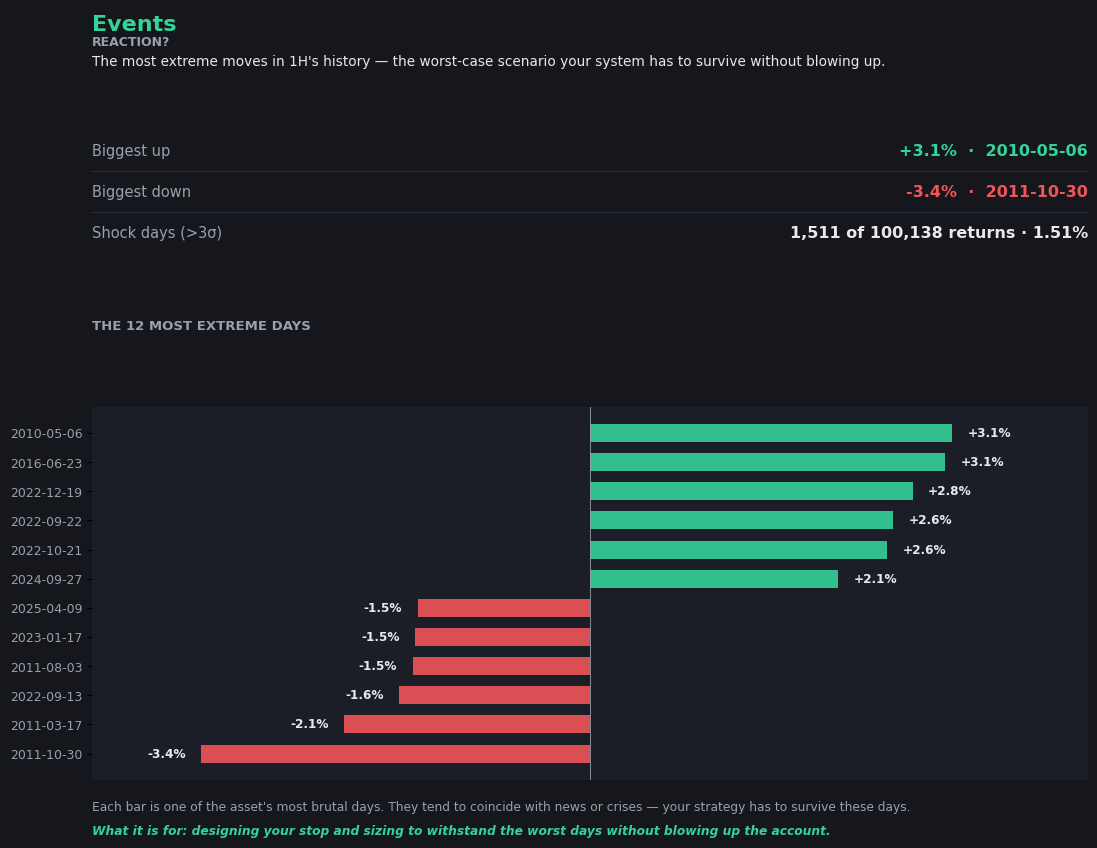

Biggest up: +3.1%
Biggest down: -3.4%
Shock days (>3σ): 1513 of 100,138 returns · 1.51%

Top 12 up days:
+3.1% - 2010-05-06
+3.1% - 2016-06-23
+2.8% - 2022-12-19
+2.6% - 2022-09-22
+2.6% - 2022-10-21
+2.1% - 2024-09-27

Top 12 down days:
-3.4% - 2011-10-30
-2.1% - 2011-03-17
-1.6% - 2022-09-13
-1.5% - 2011-08-03
-1.5% - 2023-01-17
-1.5% - 2025-04-09

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


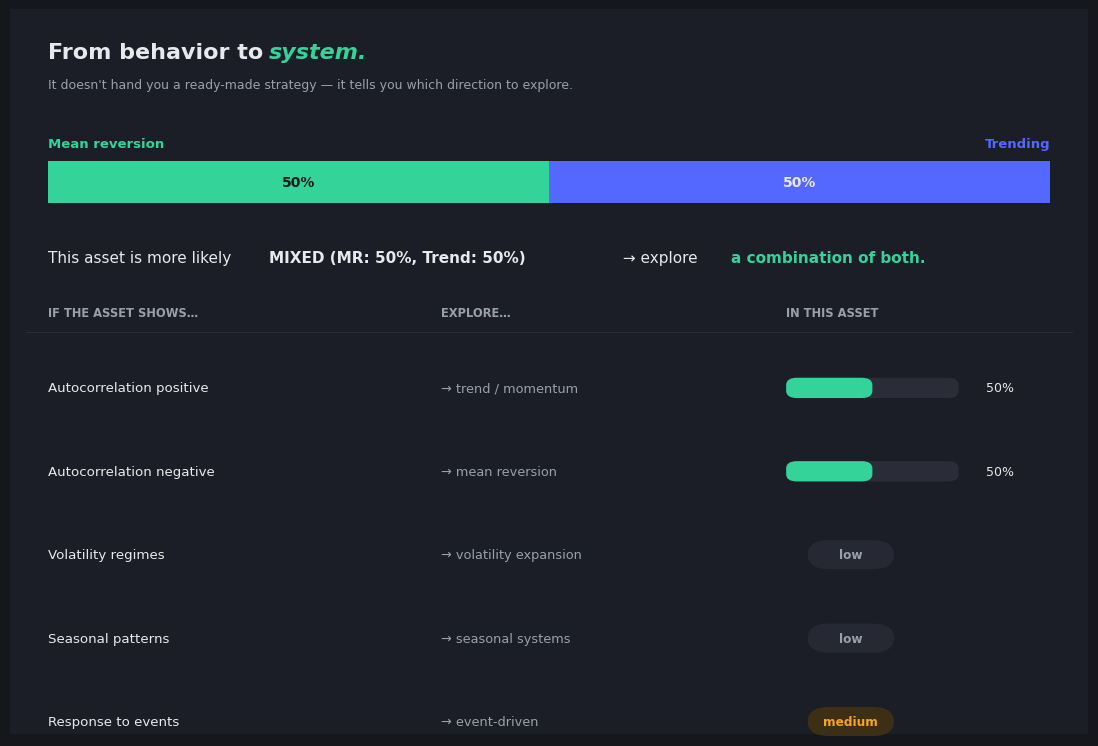


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 8.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 1.09 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 40.53 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.006

Hurst Exponent
Measures price memory. >0.5 = trending.
→ 0.504

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether 

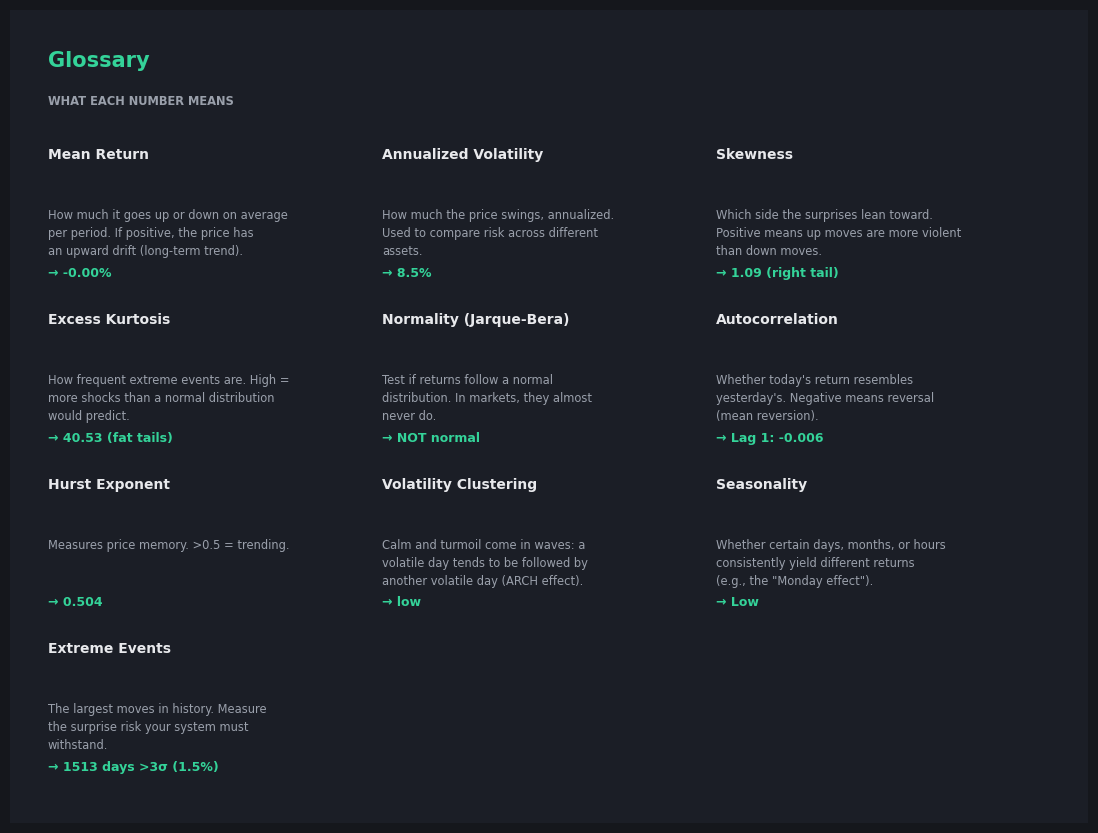




ANALYZING 4H TIMEFRAME

COMPLETE ANALYSIS: 4H
Bars: 27067
Period: 2009-09-27 16:00:00 → 2026-08-28 16:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
RANDOM WALK
Hurst 0.49
BEARISH
~-3.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.00%
Annualized volatility: 8.5%
Skewness: 0.69 (right tail)
Excess Kurtosis: 26.07 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 392 (1.4%)


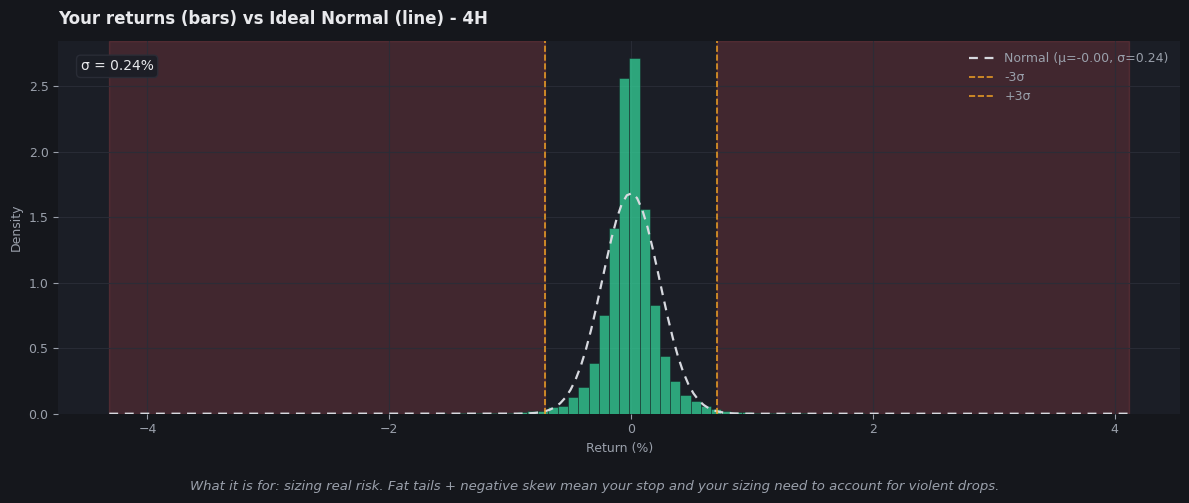


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.37x
Recent volatility (daily): 0.09%
Historical volatility (daily): 0.24%
Comes in waves? low


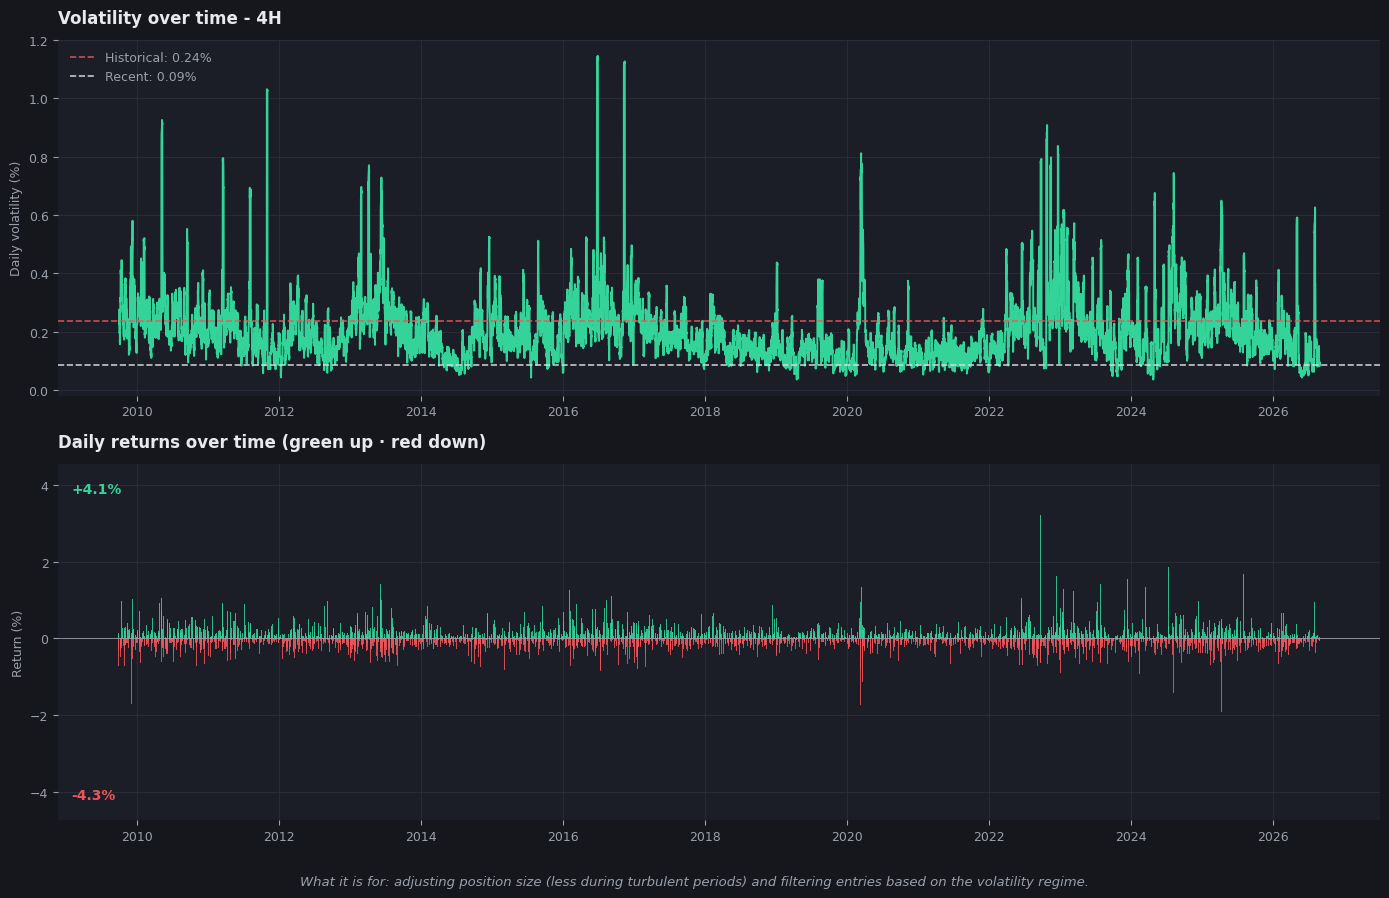


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.01 reverts
Lag 5 · vs 5 days ago: 0.02 ~0
Lag 20 · vs 20 days ago: -0.01 reverts


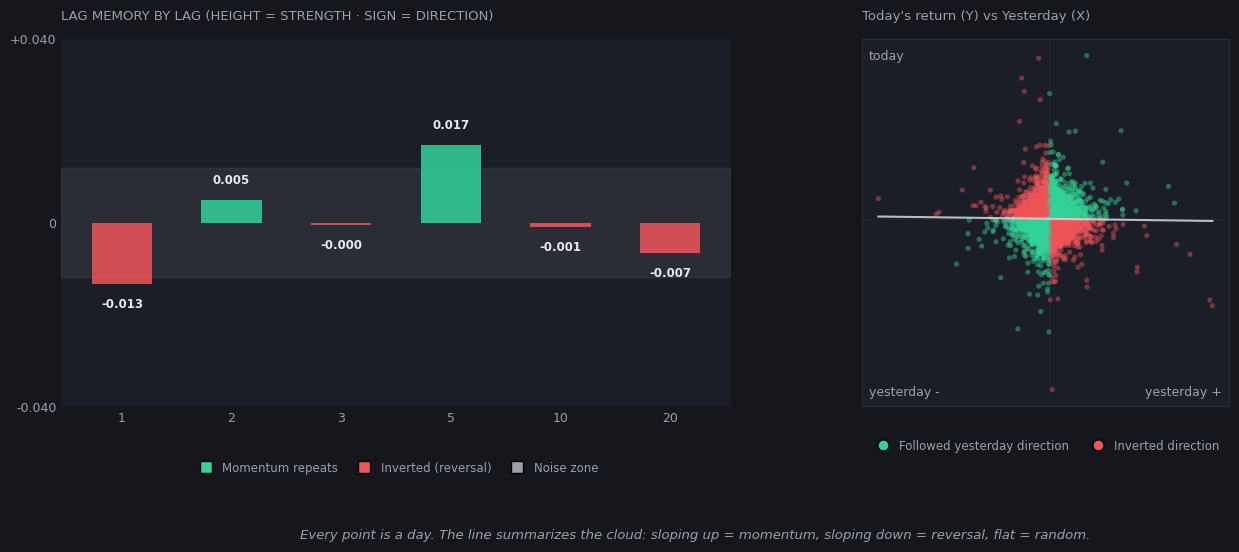


PATTERNS
SEASONALITY?


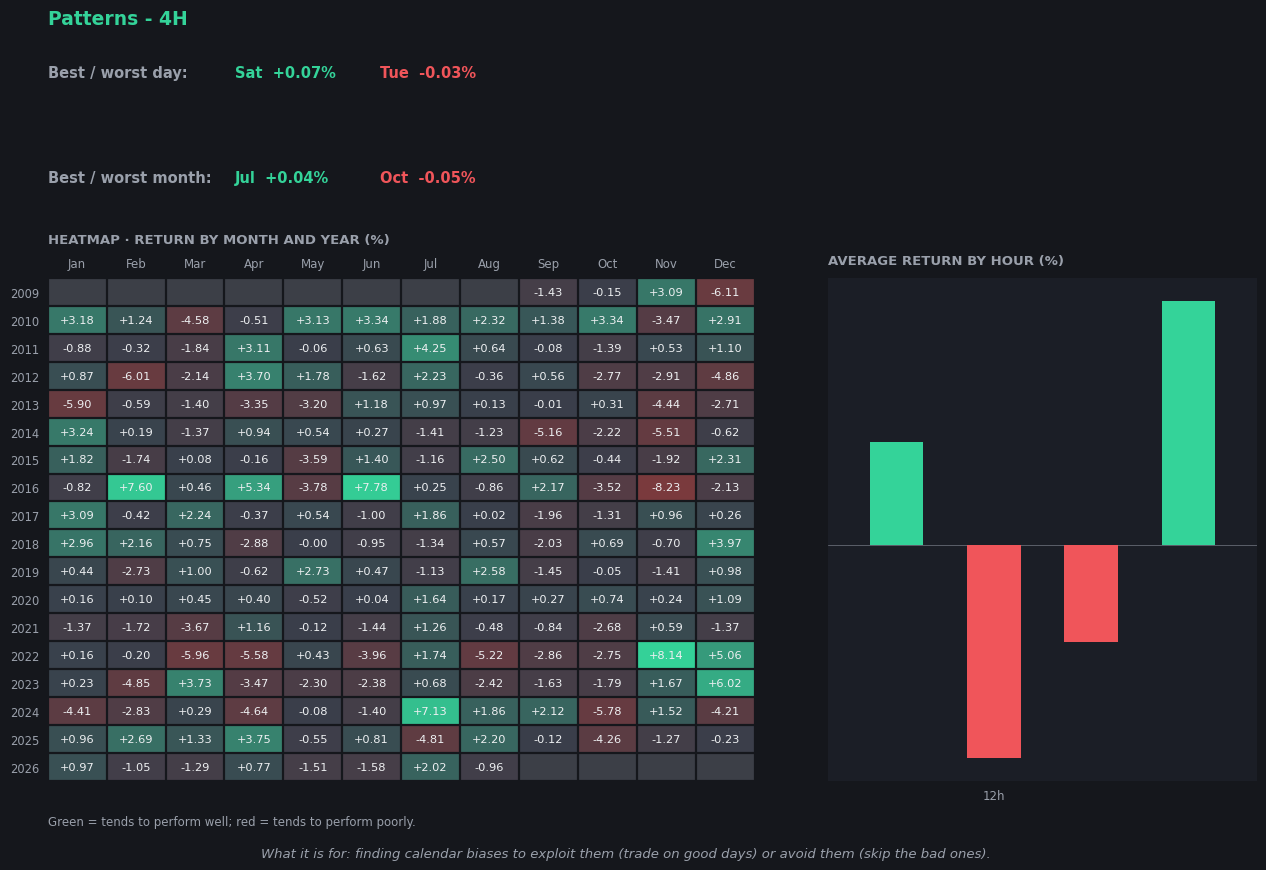


Average return by day of week (Mon-Fri, %):
Mon: -0.01%
Tue: -0.03%
Wed: -0.01%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.01%
Feb: -0.02%
Mar: -0.03%
Apr: -0.01%
May: -0.01%
Jun: 0.00%
Jul: 0.04%
Aug: 0.00%
Sep: -0.02%
Oct: -0.05%
Nov: -0.03%
Dec: 0.00%

Average return by hour (6:00-22:00, %):
08:00: 0.01%
12:00: -0.01%
16:00: -0.00%
20:00: 0.01%

EXTREME EVENTS
REACTION?


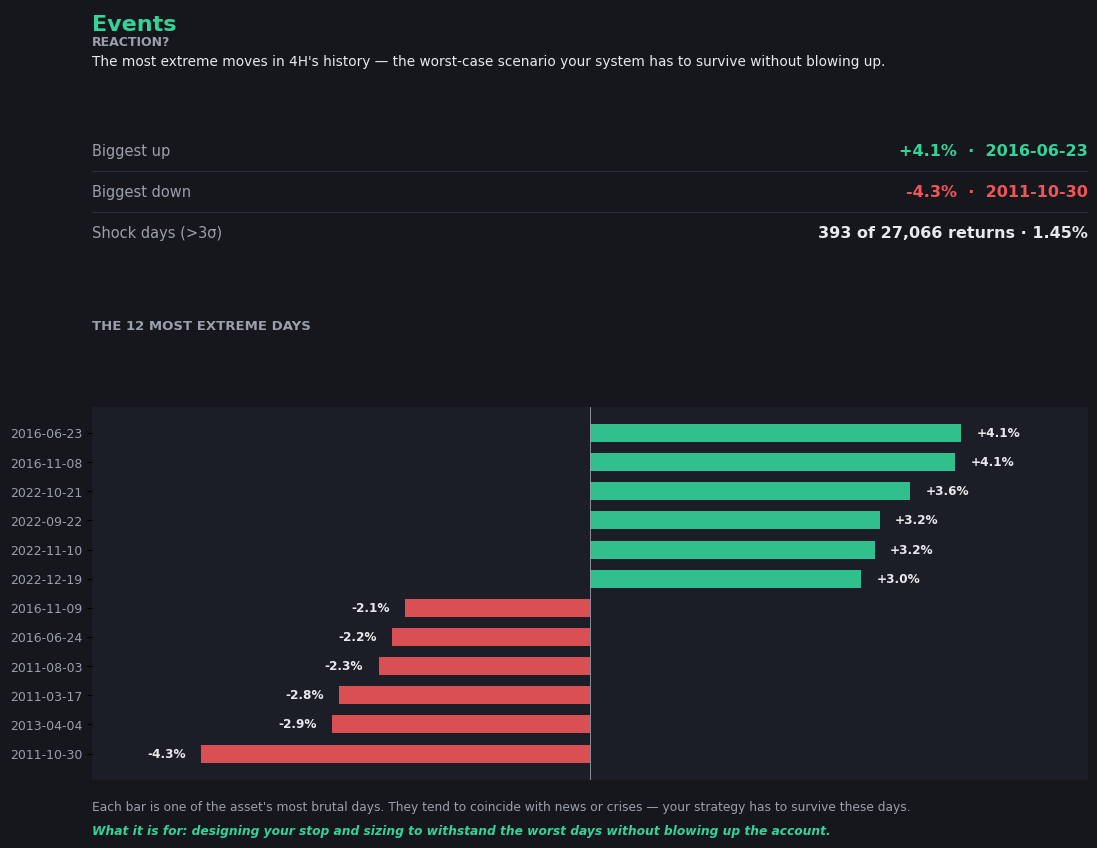

Biggest up: +4.1%
Biggest down: -4.3%
Shock days (>3σ): 392 of 27,066 returns · 1.45%

Top 12 up days:
+4.1% - 2016-06-23
+4.1% - 2016-11-08
+3.6% - 2022-10-21
+3.2% - 2022-09-22
+3.2% - 2022-11-10
+3.0% - 2022-12-19

Top 12 down days:
-4.3% - 2011-10-30
-2.9% - 2013-04-04
-2.8% - 2011-03-17
-2.3% - 2011-08-03
-2.2% - 2016-06-24
-2.1% - 2016-11-09

FROM BEHAVIOR TO SYSTEM
Mean reversion: 50%
Trending: 50%

This asset is more likely MIXED (MR: 50%, Trend: 50%) → explore a combination of both.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


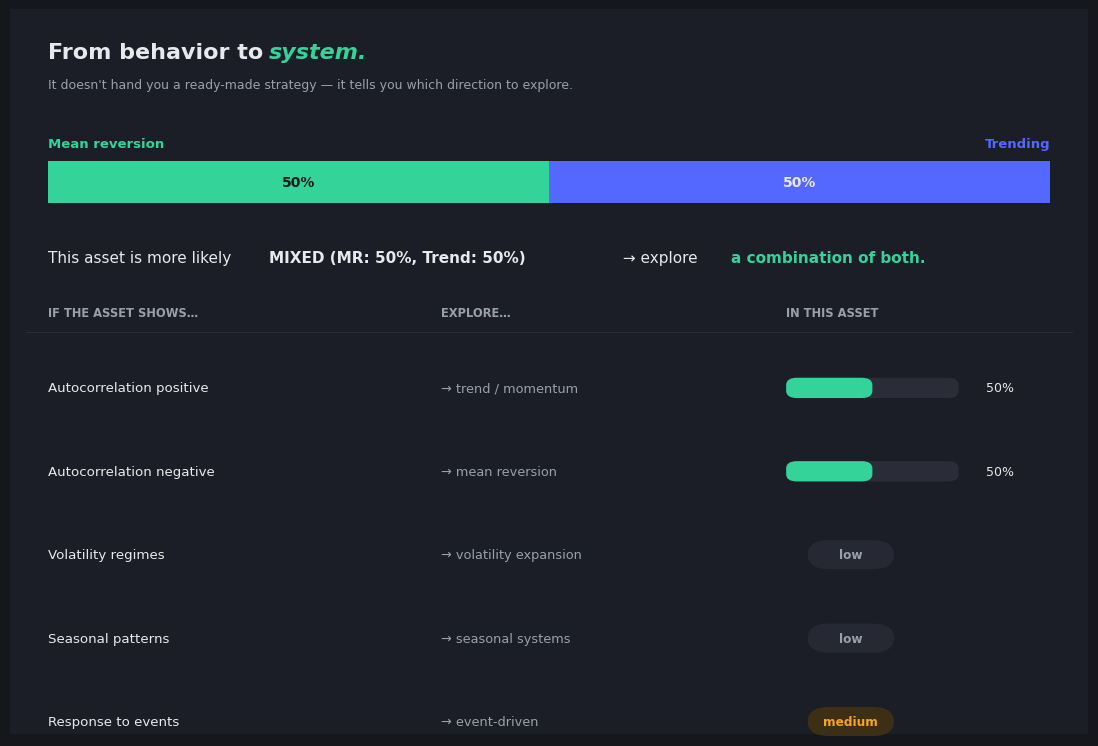


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.00%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 8.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.69 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 26.07 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.013

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.494

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether

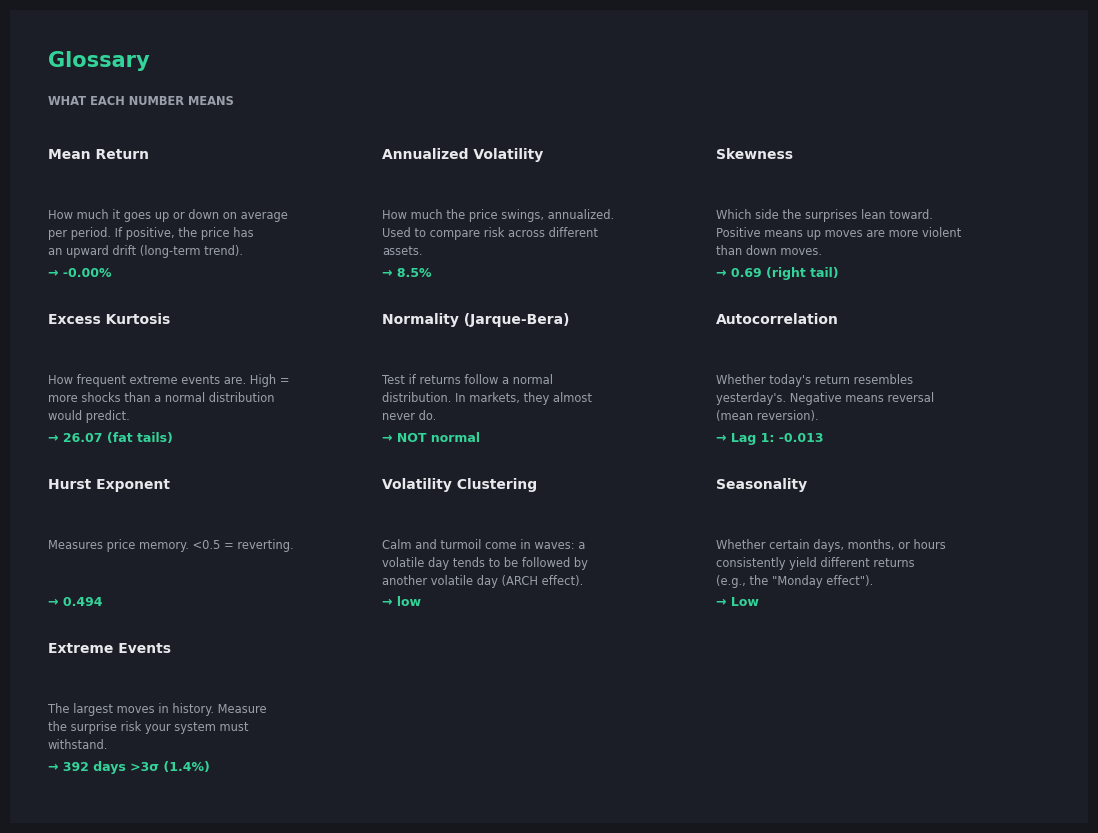




ANALYZING 1D TIMEFRAME

COMPLETE ANALYSIS: 1D
Bars: 5264
Period: 2009-09-27 00:00:00 → 2026-08-28 00:00:00

SHORT-TERM BEHAVIOR          LONG-TERM DRIFT (TREND)
MEAN REVERSION
Hurst 0.45
BEARISH
~-3.4%/year (mean return)

DISTRIBUTION
TAILS?
Mean return: -0.01%
Annualized volatility: 8.5%
Skewness: 0.15 (right tail)
Excess Kurtosis: 5.82 (fat tails)
Normality: NOT normal
Extreme days (>3σ): 69 (1.3%)


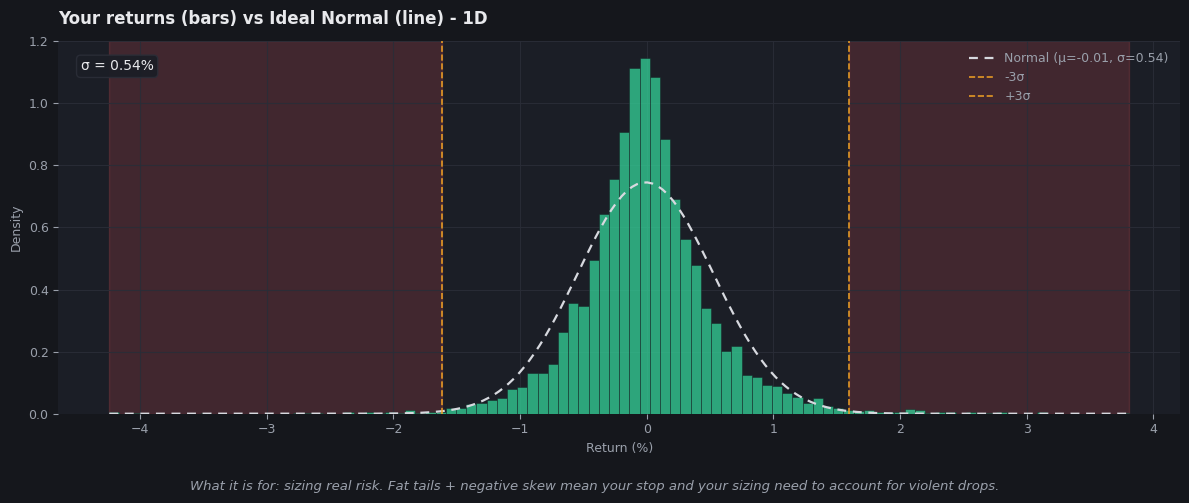


VOLATILITY
REGIMES?
Recent vs Mean vol: 0.56x
Recent volatility (daily): 0.30%
Historical volatility (daily): 0.54%
Comes in waves? low


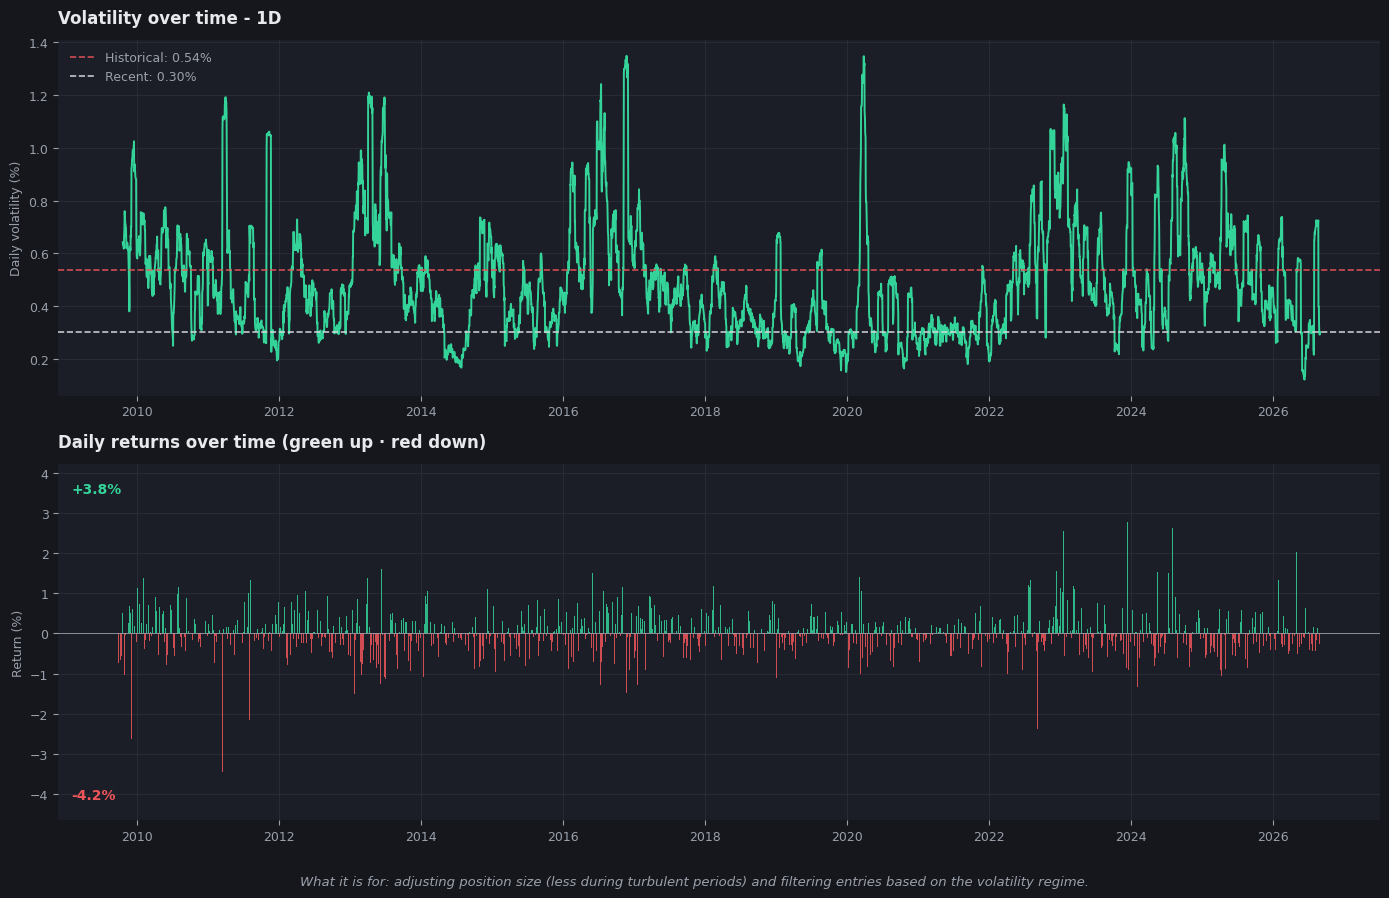


AUTOCORRELATION · MEMORY
PERSISTENCE?
Lag 1 · vs yesterday: -0.02 reverts
Lag 5 · vs 5 days ago: 0.03 ~0
Lag 20 · vs 20 days ago: -0.01 reverts


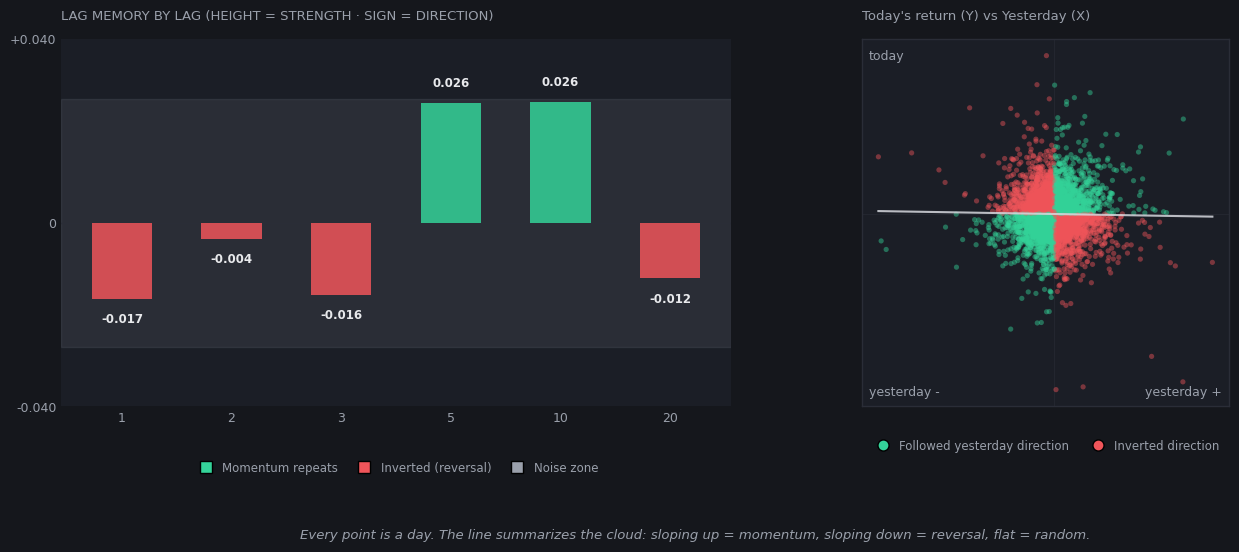


PATTERNS
SEASONALITY?


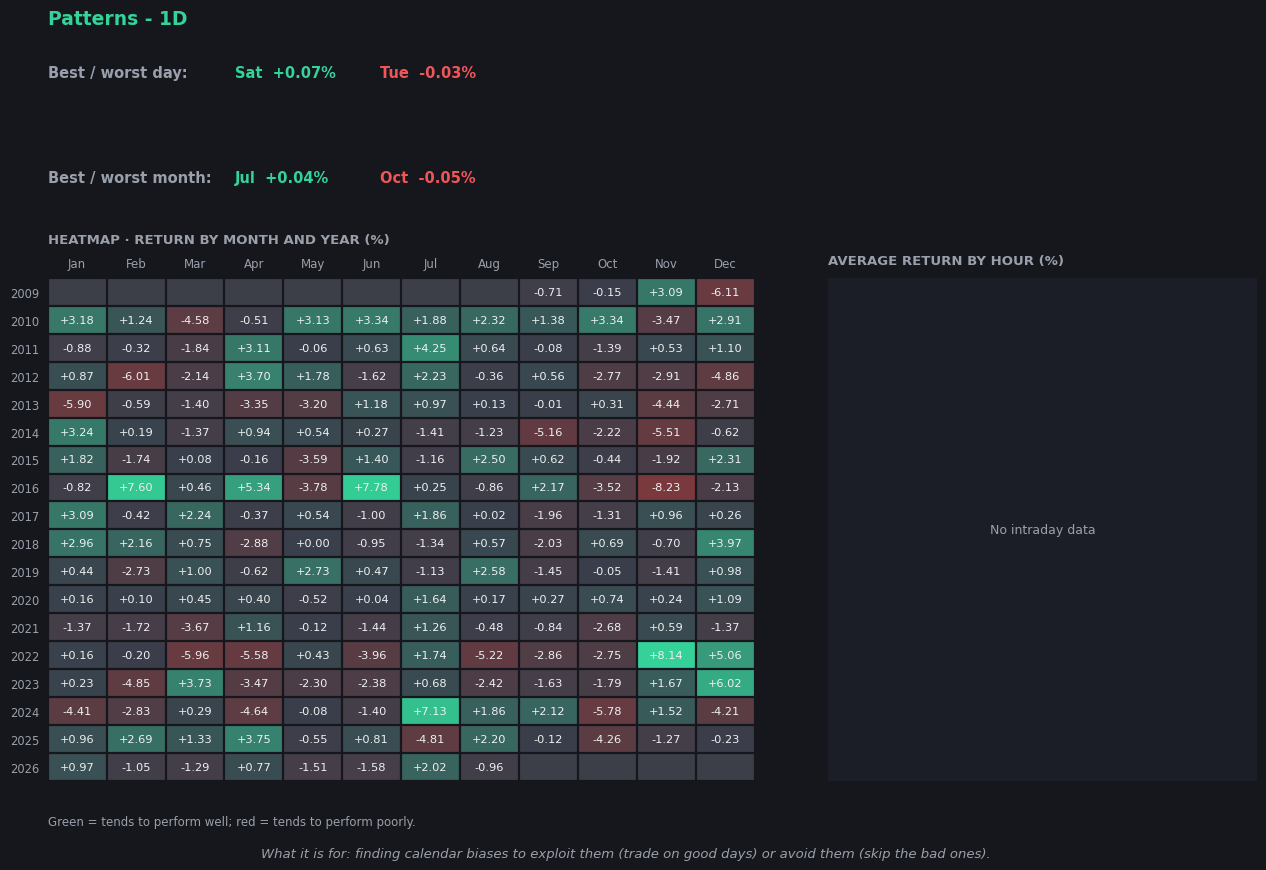


Average return by day of week (Mon-Fri, %):
Mon: -0.01%
Tue: -0.03%
Wed: -0.01%
Thu: 0.01%
Fri: -0.00%

Average return by month (%):
Jan: 0.01%
Feb: -0.02%
Mar: -0.03%
Apr: -0.01%
May: -0.01%
Jun: 0.00%
Jul: 0.04%
Aug: 0.00%
Sep: -0.02%
Oct: -0.05%
Nov: -0.03%
Dec: 0.00%

EXTREME EVENTS
REACTION?


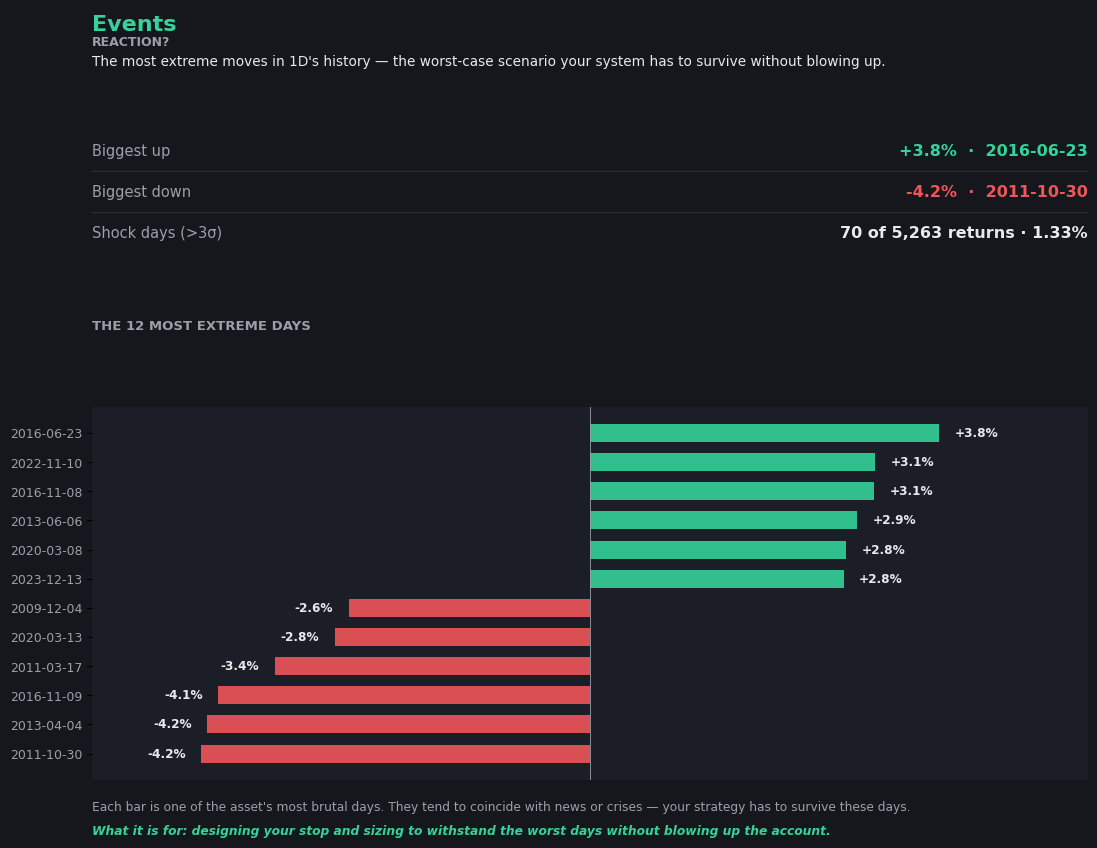

Biggest up: +3.8%
Biggest down: -4.2%
Shock days (>3σ): 69 of 5,263 returns · 1.31%

Top 12 up days:
+3.8% - 2016-06-23
+3.1% - 2022-11-10
+3.1% - 2016-11-08
+2.9% - 2013-06-06
+2.8% - 2020-03-08
+2.8% - 2023-12-13

Top 12 down days:
-4.2% - 2011-10-30
-4.2% - 2013-04-04
-4.1% - 2016-11-09
-3.4% - 2011-03-17
-2.8% - 2020-03-13
-2.6% - 2009-12-04

FROM BEHAVIOR TO SYSTEM
Mean reversion: 70%
Trending: 30%

This asset is more likely MEAN REVERSION → explore fade / reversal.

--------------------------------------------------
If the asset shows...	Explore...	In this asset
--------------------------------------------------
Autocorrelation neutral	→ mean reversion	~0%
Volatility regimes	→ volatility expansion	low
Seasonal patterns	→ seasonal systems	low
Response to events	→ event-driven	medium


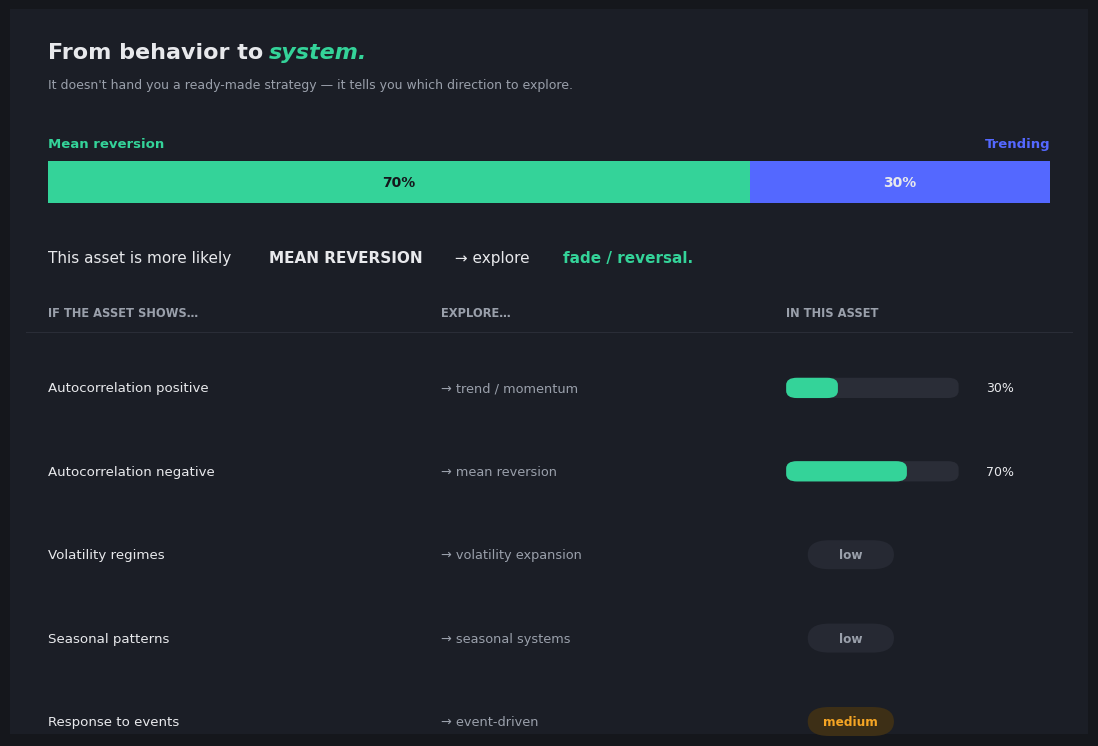


GLOSSARY
WHAT EACH NUMBER MEANS

Mean Return
How much it goes up or down on average per period. If positive, the price has an upward drift (long-term trend).
→ -0.01%

Annualized Volatility
How much the price swings, annualized. Used to compare risk across different assets.
→ 8.5%

Skewness
Which side the surprises lean toward. Positive means up moves are more violent than down moves.
→ 0.15 (right tail)

Excess Kurtosis
How frequent extreme events are. High = more shocks than a normal distribution would predict.
→ 5.82 (fat tails)

Normality (Jarque-Bera)
Test if returns follow a normal distribution. In markets, they almost never do.
→ NOT normal

Autocorrelation
Whether today's return resembles yesterday's. Negative means reversal (mean reversion).
→ Lag 1: -0.017

Hurst Exponent
Measures price memory. <0.5 = reverting.
→ 0.447

Volatility Clustering
Calm and turmoil come in waves: a volatile day tends to be followed by another volatile day (ARCH effect).
→ low

Seasonality
Whether 

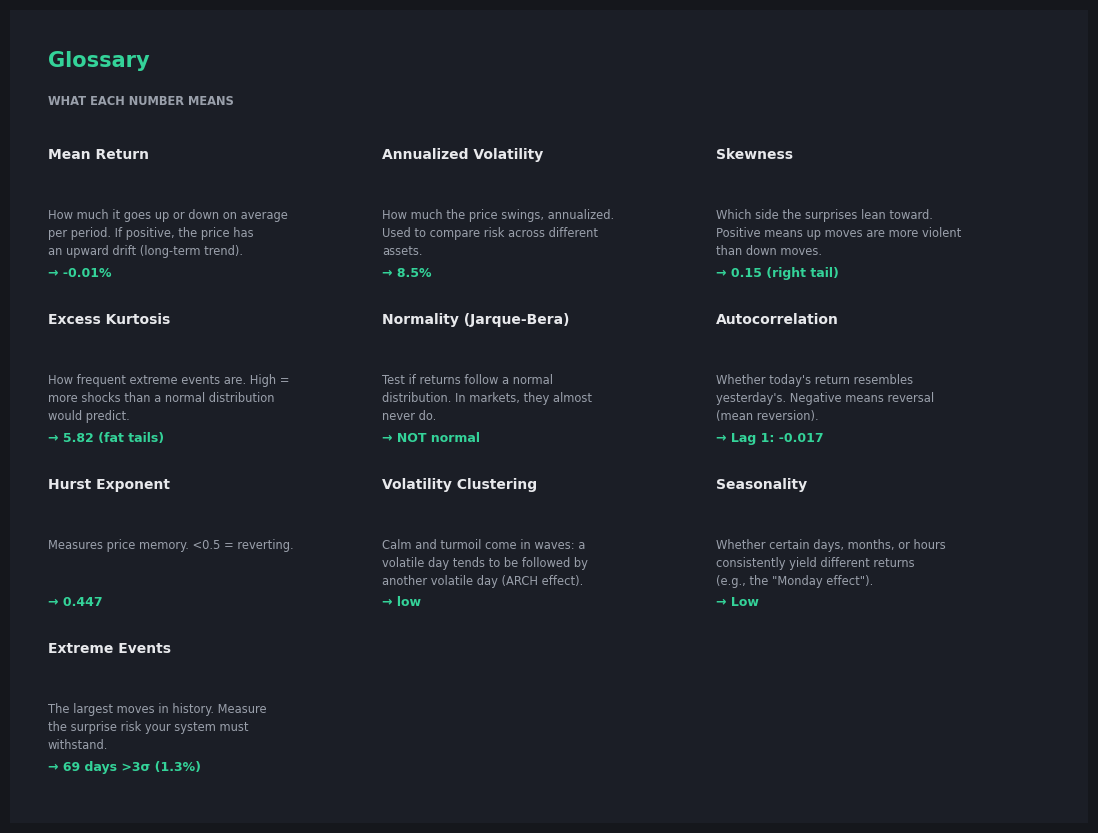




All timeframes analyzed successfully!


In [20]:
# Analyze 15min (raw data)
print("\n" + "="*70)
print("ANALYZING 15MIN TIMEFRAME")
print("="*70)
results_15min = analyze_timeframe_detailed(timeframes['15min'], '15min')

# Analyze 1H
print("\n" + "="*70)
print("ANALYZING 1H TIMEFRAME")
print("="*70)
results_1h = analyze_timeframe_detailed(timeframes['1H'], '1H')

# Analyze 4H
print("\n" + "="*70)
print("ANALYZING 4H TIMEFRAME")
print("="*70)
results_4h = analyze_timeframe_detailed(timeframes['4H'], '4H')

# Analyze 1D
print("\n" + "="*70)
print("ANALYZING 1D TIMEFRAME")
print("="*70)
results_1d = analyze_timeframe_detailed(timeframes['1D'], '1D')

print("\nAll timeframes analyzed successfully!")

## SUMMARY OF RESULTS

In [21]:
summary_df = pd.DataFrame([
    results_15min,
    results_1h,
    results_4h,
    results_1d
])

summary_df = summary_df.set_index('name')

print("\n" + "="*70)
print("SUMMARY OF KEY METRICS ACROSS TIMEFRAMES")
print("="*70)
print(summary_df[['mean_ret', 'vol_ann', 'skew', 'kurt', 'hurst', 'mr_pct', 'trend_pct']])

# Optional: Show full summary if you want all columns
print("\n" + "-"*70)
print("FULL SUMMARY (all metrics)")
print("-"*70)
print(summary_df)


SUMMARY OF KEY METRICS ACROSS TIMEFRAMES
       mean_ret   vol_ann      skew        kurt     hurst  mr_pct  trend_pct
name                                                                        
15min -0.000126  8.495845  1.727627  107.428057  0.504195    50.0       50.0
1H    -0.000509  8.495845  1.089010   40.531016  0.504159    50.0       50.0
4H    -0.001900  8.495845  0.689461   26.069277  0.493993    50.0       50.0
1D    -0.009641  8.495845  0.154280    5.817243  0.447080    70.0       30.0

----------------------------------------------------------------------
FULL SUMMARY (all metrics)
----------------------------------------------------------------------
       mean_ret   vol_ann      skew        kurt      normal  pct_extreme  \
name                                                                       
15min -0.000126  8.495845  1.727627  107.428057  NOT normal     1.375710   
1H    -0.000509  8.495845  1.089010   40.531016  NOT normal     1.510915   
4H    -0.001900  8.495

# END OF ANALYSIS

In [22]:
print("\n" + "="*70)
print("ANALYSIS COMPLETE")
print("="*70)
print("All plots and statistics have been generated.")
print("The reusable functions from utils.py made this analysis concise and portable.")
print("\nSummary of key findings by timeframe:")
print("-"*50)
for idx, row in summary_df.iterrows():
    print(f"{idx}:")
    print(f"  Hurst: {row['hurst']:.3f} → {'Mean Reversion' if row['hurst'] < 0.45 else 'Trending' if row['hurst'] > 0.55 else 'Random Walk'}")
    print(f"  System bias: {row['mr_pct']:.0f}% Mean Reversion / {row['trend_pct']:.0f}% Trending")
    print(f"  Volatility (ann): {row['vol_ann']:.1f}%")
    print(f"  Extreme events (>3σ): {row['pct_extreme']:.2f}% of days")
    print("-"*50)


ANALYSIS COMPLETE
All plots and statistics have been generated.
The reusable functions from utils.py made this analysis concise and portable.

Summary of key findings by timeframe:
--------------------------------------------------
15min:
  Hurst: 0.504 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 8.5%
  Extreme events (>3σ): 1.38% of days
--------------------------------------------------
1H:
  Hurst: 0.504 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 8.5%
  Extreme events (>3σ): 1.51% of days
--------------------------------------------------
4H:
  Hurst: 0.494 → Random Walk
  System bias: 50% Mean Reversion / 50% Trending
  Volatility (ann): 8.5%
  Extreme events (>3σ): 1.45% of days
--------------------------------------------------
1D:
  Hurst: 0.447 → Mean Reversion
  System bias: 70% Mean Reversion / 30% Trending
  Volatility (ann): 8.5%
  Extreme events (>3σ): 1.31% of days
----------------------------